# Notebook 02 - Q3: Phân tích Chuyên sâu Câu hỏi Q3 (Tỷ suất đồng xuất hiện ROR Hoạt chất x Triệu chứng)
**Đề tài:** Phân tích Sự cố Bất lợi Thuốc Thú y (OpenFDA Animal & Veterinary Adverse Events) giai đoạn 2025 và Đối chiếu Xu hướng 2026 (Q1)

**Môn học:** CSC17104 – Lập trình cho Khoa học Dữ liệu  
**Nhóm thực hiện:** Global Ban  
**Thành viên phụ trách:** Huỳnh Tuấn Kiệt
**Phản biện chéo:** Trần Ngô Uyên Nhi 
**Liên kết Master Hub:** [Notebook 02: Master Hub (Mục 3.3 Question Formulation & D1–D6)](02_analysis.ipynb)

In [1]:
import sys
import re
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_processed
from src.preprocessing import (
    KEY,
    load_clean_tables,
    run_core_preprocessing,
    save_clean_tables,
    log_row_count_change,
)
from src.visualization import set_project_plot_style

set_project_plot_style()

In [2]:
# Tải 4 bảng dữ liệu sạch chuẩn hóa từ pipeline tiền xử lý lõi Task T14 (src/preprocessing.py)
RAW_PROC_DIR = PROJECT_ROOT / "data" / "processed"
CLEAN_PROC_DIR = RAW_PROC_DIR / "clean"

raw_tables = load_processed(RAW_PROC_DIR)
if not (CLEAN_PROC_DIR / "reports.csv").exists():
    clean_tables, _ = run_core_preprocessing(raw_tables, verbose=True)
    save_clean_tables(clean_tables, CLEAN_PROC_DIR)
else:
    clean_tables = load_clean_tables(CLEAN_PROC_DIR)

reports = clean_tables["reports"]
drugs = clean_tables["drugs"]
reactions = clean_tables["reactions"]
outcomes = clean_tables["outcomes"]

print("=== ĐỐI CHIẾU QUY MÔ DỮ LIỆU THÔ (data/processed) -> SẠCH LÕI T14 (data/processed/clean) ===")
for name in ("reports", "drugs", "reactions", "outcomes"):
    log_row_count_change(
        f"T14_core_{name}",
        len(raw_tables[name]),
        len(clean_tables[name]),
        "Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)",
    )
print(
    f"\n[Clean Data Ready] Reports: {reports.shape}, Drugs: {drugs.shape}, "
    f"Reactions: {reactions.shape}, Outcomes: {outcomes.shape}"
)

=== ĐỐI CHIẾU QUY MÔ DỮ LIỆU THÔ (data/processed) -> SẠCH LÕI T14 (data/processed/clean) ===
[T14_core_reports] Rows: 94,412 -> 93,812 (Change: -600 | -0.64%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_drugs] Rows: 174,123 -> 173,221 (Change: -902 | -0.52%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_reactions] Rows: 270,244 -> 267,848 (Change: -2,396 | -0.89%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_outcomes] Rows: 85,143 -> 84,543 (Change: -600 | -0.70%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)

[Clean Data Ready] Reports: (93812, 53), Drugs: (173221, 31), Reactions: (267848, 8), Outcomes: (84543, 6)


---
## Câu hỏi Q3: Tỷ suất Đồng xuất hiện (ROR) Hoạt chất x Triệu chứng (Safety Issue vs Lack of Efficacy)

### Phát biểu câu hỏi và Động lực
- **Phát biểu câu hỏi:**  
  > **"Các hoạt chất (`active_ingredients`) và đường dùng (`route`) nào có tỷ suất đồng xuất hiện (Reporting Odds Ratio) đặc trưng nhất với từng phản ứng cụ thể, và pattern này khác biệt ra sao giữa nhóm Safety Issue và Lack Of Expected Effectiveness trong năm 2025?"**
- **Người quan tâm & Quyết định hỗ trợ (Target Users & Decisions):**
  - **Chuyên gia Cảnh giác dược (FDA CVM) & Bộ phận R&D Dược phẩm Thú y:** Cần tách biệt rõ **tín hiệu báo cáo mất cân đối mạnh (*strong disproportionality reporting signals*)** thuộc nhóm **biến cố bất lợi lâm sàng thực sự (*Safety Issue*)** (như tăng thể ceton beta-hydroxybutyrate/nhiễm toan ceton khi dùng thuốc ức chế SGLT2 ở mèo, rối loạn điện giải Na:K/suy vỏ thượng thận khi dùng thuốc nội tiết ở chó, điếc/mất thính lực khi dùng thuốc nhỏ tai, hay mất điều hòa vận động/uống nhiều ở thuốc kháng thể đơn dòng) khỏi nhóm **kém/giảm hiệu quả thuốc mong đợi (*Lack Of Expected Effectiveness — LOEE*)** (như thất bại dự phòng bệnh Lyme *Borrelia*, thất bại kiểm soát bệnh hô hấp phức hợp ở bò dẫn đến tử vong/mổ khám, hoặc giảm hiệu lực thuốc diệt bọ chét/ve/giun tim). Nếu gộp chung hai luồng này trên toàn bộ cơ sở dữ liệu, hàng chục nghìn báo cáo LOEE của thuốc ký sinh trùng sẽ làm loãng mẫu số và gây hiệu ứng che lấp (*masking/cloaking effect*) đối với các tín hiệu biến cố bất lợi đặc hiệu cơ quan.
  - **Bác sĩ thú y lâm sàng:** Nhận diện rủi ro đặc thù theo từng đường dùng thuốc (`Topical`, `Auricular (Otic)`, `Oral`, `Subcutaneous`, `Intravenous`, `Intramuscular`, `Nasal`, `Parenteral`) tách riêng giữa luồng biến cố bất lợi (`Safety Issue`) và luồng kém hiệu quả điều trị (`LOEE`) để tư vấn giám sát triệu chứng mục tiêu sau cấp thuốc.
- **Tiêu chí độ sâu áp dụng (Mục 3.3 — bao phủ 4 tiêu chí D1, D2, D4, D5):**
  - **`D1` (Combining data):** Kết nối 3 bảng quan hệ `reports`, `drugs`, `reactions` qua khóa `unique_aer_id_number`; kiểm tra toàn vẹn khóa nối và **chống bùng nổ tổ hợp (Cartesian explosion)** bằng cách chuẩn hóa danh pháp hoạt chất (gộp cả các tên thương mại/chủng biểu hiện của cùng một kháng nguyên sinh học như `Recombitek Lyme - 2126.R0` và `Recombinant E. Coli BL21/ECL19` về `Borrelia Burgdorferi Ospa (Recombinant E. Coli)`) và khử trùng lặp về cấp báo cáo `(unique_aer_id_number, ingredient)`, `(unique_aer_id_number, route)` và `(unique_aer_id_number, veddra_term_name)` trước khi dựng bảng liên hợp $2 \times 2$.
  - **`D2` (Reshaping & time):** Xoay trục (`pivot_table` / `melt`) ma trận $\log_2(\text{ROR})$ đối sánh hai luồng `Safety Issue` vs. `Lack Of Expected Effectiveness` cho cả **Hoạt chất $\times$ Phản ứng** và **Đường dùng $\times$ Phản ứng**; đồng thời phân tích chuỗi thời gian theo từng quý (`2025Q1` $\rightarrow$ `2025Q4` và đối chiếu `2026Q1`) để kiểm chứng tính bền vững của các tín hiệu cảnh giác dược hàng đầu.
  - **`D4` (Controlling for a confounder):** Kiểm soát biến nhiễu **Loài vật nuôi (`species`: Chó `Dog` vs. Mèo `Cat`)** thông qua phân tầng (Stratified ROR) và ước lượng **Tỷ số chênh đồng xuất hiện hiệu chỉnh Cochran–Mantel–Haenszel ($\text{ROR}_{\text{MH}}$)** nhằm loại trừ hiện tượng nhiễu giả do thuốc chỉ định chuyên biệt theo loài.
  - **`D5` (Quantifying uncertainty):** Đánh giá trên toàn bộ không gian giả thuyết $(E, R)$ đạt ngưỡng cỡ mẫu tối thiểu ($n_{\text{exp}} \ge 50, n_{\text{rea}} \ge 50, a \ge 20$), ước lượng **Reporting Odds Ratio (ROR)**, **Proportional Reporting Ratio (PRR)**, khoảng tin cậy **95% CI** theo phương pháp Woolf/Haldane–Anscombe, kiểm định $\chi^2$ hiệu chỉnh Yates và kiểm soát tỷ lệ phát hiện sai đa kiểm định trên toàn không gian $M$ bằng **Benjamini–Hochberg FDR ($q_{\text{FDR}} < 0.05$)**.


### 1. Tiền xử lý cho Q3

Tuân thủ **Mục 3.4 (Data Analysis — Preprocessing)**, quy trình tiền xử lý chuyên biệt cho Q3 kế thừa trực tiếp 4 bảng sạch từ **Task T14 (`data/processed/clean/`)** và thực hiện 5 bước biến đổi có ghi vết số dòng (`log_row_count_change`):

1. **Bước 1.1 — Lọc khung thời gian phân tích năm 2025 (`2025q1`–`2025q4`):**
   - Giữ lại các báo cáo thú y trong 4 quý năm 2025 để phân tích cấu trúc đồng xuất hiện cả năm; đồng thời trích riêng tập `2026q1` để đối chiếu độ ổn định tín hiệu theo thời gian ở tiêu chí **D2**.
2. **Bước 1.2 — Phân nhóm bản chất biến cố (`event_category`) từ `type_of_information`:**
   - Ánh xạ các nhãn chi tiết về 4 nhóm chuẩn: **`Safety Issue`** (bao gồm cả *Safety Issue (Clinical Studies)*), **`Lack Of Expected Effectiveness`** (bao gồm cả *LOEE (Clinical Studies)*), **`Both Safety & LOEE`**, và **`Product/Manufacturing Defect`**.
   - Loại bỏ các báo cáo chỉ phản ánh lỗi bao bì/sản xuất mà không có biến cố lâm sàng (`Product/Manufacturing Defect` và `Other/Unknown`) khỏi tập phân tích dược lý lâm sàng.
3. **Bước 1.3 — Đồng bộ bảng `drugs` & Lọc bỏ dòng khuyết hoạt chất hiệu dụng (`active_ingredients_clean`):**
   - Kết nối bảng `drugs` với tập báo cáo lâm sàng năm 2025 và loại bỏ các dòng thuốc có `active_ingredients_clean` là `NaN` (đã được Task T14 gom từ `NaN` gốc và các chuỗi thiếu ẩn như `'Noinformationsupplied'`, `'Unknown'`, `'Unknown Medication'`, `'*(Unknown)'`).
4. **Bước 1.4 — Chuẩn hóa danh pháp Hoạt chất đơn lẻ (Canonicalization) & Đường dùng thuốc từ tập `drg_q3_valid`:**
   - **Tách và chuẩn hóa hoạt chất:** Tách các chế phẩm đa hoạt chất nối bằng `';'`, `','`, `'/'` hoặc `'+'` (ví dụ `Pyrantel Pamoate;Sarolaner`, `Genta/Momet/Clotrim Ear Oint`, `Gentamicin + Mometasone + Clotrimazole`); loại bỏ hậu tố gốc muối (`pamoate`, `maleate`, `citrate`, `hydrochloride`, `monohydrate`, `oxime`...) và thông số hàm lượng/dạng bào chế (`eardrops`, `ear oint`, `spot-on solution`...).
   - **Ánh xạ danh pháp sinh học và tên viết tắt (`INGREDIENT_ALIASES`):**
     - Hợp nhất tên thương mại kèm mã giấy phép vắc-xin USDA `Recombitek Lyme - 2126.R0` và hệ chủng vi khuẩn biểu hiện `Recombinant E. Coli Bl21` / `Recombinant E. Coli Ecl19` về cùng một thực thể kháng nguyên sinh học **`Borrelia Burgdorferi Ospa (Recombinant E. Coli)`** *(kháng nguyên protein màng ngoài OspA không phân nhóm của xoắn khuẩn Borrelia burgdorferi được tái tổ hợp và biểu hiện trên chủng Escherichia coli BL21 và ECL19 trong vắc-xin phòng bệnh Lyme ở chó)*. Việc hợp nhất này khắc phục triệt để hiện tượng tách đôi thực thể khiến ô $b = 0$ làm phình giả tạo giá trị ROR.
     - Chuẩn hóa các tên viết tắt trong chế phẩm nhỏ tai/ký sinh trùng (`Genta` $\rightarrow$ `Gentamicin`, `Momet`/`Mometa` $\rightarrow$ `Mometasone Furoate`, `Clotrim` $\rightarrow$ `Clotrimazole`, `Posacon`/`Posaco` $\rightarrow$ `Posaconazole`, `Orbiflox` $\rightarrow$ `Orbifloxacin`, `Betamet` $\rightarrow$ `Betamethasone`, `Pzq` $\rightarrow$ `Praziquantel`, `Anti-IL31 mAb` $\rightarrow$ `Lokivetmab`) và lọc bỏ các token mã chủng virus đi kèm dấu phẩy/gạch chéo (`RLB 106`, `PI3 EBK-1`, `EBHT-1 Strain AL-IM`).
   - **Đồng bộ bảng đường dùng (`rep_route_q3`):** Trích xuất trực tiếp từ tập `drg_q3_valid` đã đồng bộ chuẩn hóa, gọi `.dropna(subset=["route"])` trước khi lọc `.ne("Unknown")` và khử trùng lặp cấp `(unique_aer_id_number, route)` để đảm bảo mẫu số báo cáo nhất quán với tập hoạt chất.
5. **Bước 1.5 — Kết nối với bảng `reactions` (Tiêu chí D1) & Kiểm định chống bùng nổ tổ hợp:**
   - Khử trùng lặp theo `(unique_aer_id_number, veddra_term_name)` và thực hiện phép nối có kiểm soát ở cấp báo cáo duy nhất.


In [3]:
# ===== 1. Thực thi Tiền xử lý chuyên biệt cho Q3 kèm log_row_count_change =====
QUARTERS_2025 = ("2025q1", "2025q2", "2025q3", "2025q4")

# Bước 1.1: Lọc báo cáo năm 2025 (4 quý)
rep_2025_all = reports[reports["quarter"].isin(QUARTERS_2025)].copy()
log_row_count_change(
    "Q3_step1_filter_2025_reports",
    len(reports),
    len(rep_2025_all),
    "Lọc báo cáo thú y thuộc 4 quý năm 2025 (2025q1-2025q4)",
)

# Bước 1.2: Phân loại bản chất biến cố từ type_of_information
def classify_event_category(val: str) -> str:
    s = str(val).strip().lower()
    has_safety = "safety" in s
    has_loee = ("lack of expected effectiveness" in s) or ("loee" in s)
    if has_safety and not has_loee and "defect" not in s:
        return "Safety Issue"
    if has_loee and not has_safety and "defect" not in s:
        return "Lack Of Expected Effectiveness"
    if has_safety and has_loee and "defect" not in s:
        return "Both Safety & LOEE"
    if "defect" in s:
        return "Product/Manufacturing Defect"
    return "Other/Unknown"

rep_2025_all["event_category"] = rep_2025_all["type_of_information"].map(classify_event_category)

CLINICAL_CATEGORIES = ("Safety Issue", "Lack Of Expected Effectiveness", "Both Safety & LOEE")
rep_q3 = rep_2025_all[rep_2025_all["event_category"].isin(CLINICAL_CATEGORIES)].copy()
log_row_count_change(
    "Q3_step2_exclude_product_defects",
    len(rep_2025_all),
    len(rep_q3),
    "Loại bỏ báo cáo lỗi sản xuất/bao bì (Product Defect) và Other/Unknown không phản ánh tương tác dược lý",
)

# Bước 1.3: Đồng bộ bảng drugs với tập báo cáo lâm sàng 2025 & lọc dòng có hoạt chất hợp lệ
drg_2025 = drugs[drugs[KEY].isin(rep_q3[KEY])].copy()
log_row_count_change(
    "Q3_step3a_sync_drugs_2025_clinical",
    len(drugs),
    len(drg_2025),
    "Giữ các lượt thuốc thuộc tập báo cáo lâm sàng năm 2025",
)

drg_q3_valid = drg_2025.dropna(subset=["active_ingredients_clean"]).copy()
log_row_count_change(
    "Q3_step3b_drop_missing_active_ing",
    len(drg_2025),
    len(drg_q3_valid),
    "Loại bỏ dòng thuốc khuyết active_ingredients_clean (NaN và thiếu ẩn đã chuẩn hóa ở T14)",
)

# Bước 1.4: Tách đa hoạt chất & chuẩn hóa danh pháp hoạt chất gốc (Canonicalization)
INGREDIENT_STRIP_RE = re.compile(
    r"\b(?:as\s+pamoate\s+salt|pamoate|maleate|citrate|hydrochloride|hcl|sodium|potassium|"
    r"calcium|acetate|sulfate|sulphate|phosphate|tartrate|mesylate|besylate|fumarate|"
    r"succinate|benzoate|lactate|gluconate|valerate|propionate|palmitate|stearate|"
    r"monohydrate|dihydrate|trihydrate|anhydrous|proline|oxime|usp|"
    r"chewable|tablets?|chews?|spot[\-\s]*on|solutions?|powders?|for|inj(?:ectable|ection)?|"
    r"susp(?:ension)?|oral|topical|drops?|eardrops?|ear|oint(?:ment)?|capsules?|gels?|creams?|ointments?|sprays?|"
    r"lot\s*#?\s*\w+|mcs)\b"
    r"|\b\d+(?:\.\d+)?\s*(?:%|(?:mg|mcg|ug|g|kg|ml|l|iu|[\-\s]*week|[\-\s]*month|[\-\s]*day)\b)"
    r"|\(\s*.*?\s*\)",
    flags=re.IGNORECASE,
)
INGREDIENT_ALIASES = {
    "Pzq": "Praziquantel",
    "Anti-Il31 Mab": "Lokivetmab",
    # Kháng nguyên OspA tái tổ hợp (Borrelia burgdorferi) biểu hiện trên E. coli BL21/ECL19 (vắc-xin Recombitek Lyme, mã USDA 2126.R0)
    "Recombinant E Coli Bl21": "Borrelia Burgdorferi Ospa (Recombinant E. Coli)",
    "Recombinant E Coli Ecl19": "Borrelia Burgdorferi Ospa (Recombinant E. Coli)",
    "Recombitek Lyme - 2126 R0": "Borrelia Burgdorferi Ospa (Recombinant E. Coli)",
    "Recombitek Lyme 2126 R0": "Borrelia Burgdorferi Ospa (Recombinant E. Coli)",
    # Chuẩn hóa tên viết tắt trong các chế phẩm nhỏ tai phối hợp
    "Genta": "Gentamicin",
    "Momet": "Mometasone Furoate",
    "Mometa": "Mometasone Furoate",
    "Mometasone": "Mometasone Furoate",
    "Clotrim": "Clotrimazole",
    "Posacon": "Posaconazole",
    "Posaco": "Posaconazole",
    "Orbiflox": "Orbifloxacin",
    "Betamet": "Betamethasone",
    # Chuẩn hóa vắc-xin virus hô hấp bò (IBR / PI3 / BRSV) và lọc bỏ mã chủng virus đi kèm dấu phẩy/gạch chéo
    "Bovine Respiratory Syncyti": "Bovine Respiratory Syncytial Virus",
    "Bovine Parainfluenza 3": "Bovine Parainfluenza 3 Virus",
    "Bovine Parainfluenza Virus": "Bovine Parainfluenza 3 Virus",
    "Rlb 106": "",
    "Pi3 Ebk-1": "",
    "Ebht-1 Strain Al-Im": "",
}

def canonicalize_ingredient(token: str) -> str:
    s = str(token).replace("\xa0", " ")
    s = INGREDIENT_STRIP_RE.sub(" ", s)
    s = re.sub(r"[^a-zA-Z0-9\-\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip().title()
    s = re.sub(r"^[\-\s]+|[\-\s]+$", "", s)
    if "Recombitek Lyme" in s or "Recombinant E Coli" in s:
        return "Borrelia Burgdorferi Ospa (Recombinant E. Coli)"
    return INGREDIENT_ALIASES.get(s, s)

drg_exploded = (
    drg_q3_valid[[KEY, "route", "active_ingredients_clean"]]
    .assign(raw_token=lambda d: d["active_ingredients_clean"].str.replace("\xa0", " ").str.split(r"[;,/+]"))
    .explode("raw_token")
)
drg_exploded["ingredient"] = drg_exploded["raw_token"].map(canonicalize_ingredient)
drg_exploded = drg_exploded[drg_exploded["ingredient"].str.len() > 2].copy()
log_row_count_change(
    "Q3_step4a_explode_combination_drugs",
    len(drg_q3_valid),
    len(drg_exploded),
    "Tách thuốc đa thành phần (;,/+) thành từng hoạt chất đơn lẻ đã chuẩn hóa gốc muối/hàm lượng/kháng nguyên",
)

rep_ing_q3 = drg_exploded[[KEY, "ingredient"]].drop_duplicates().copy()
log_row_count_change(
    "Q3_step4b_dedup_report_ingredient",
    len(drg_exploded),
    len(rep_ing_q3),
    "Khử trùng lặp cấp (unique_aer_id_number, ingredient) để chống bùng nổ tổ hợp khi nối với reactions",
)

# Bước 1.4c: Chuẩn bị bảng đường dùng cấp báo cáo từ tập drg_q3_valid đã đồng bộ (kiểm tra dropna trước .ne('Unknown'))
rep_route_q3 = (
    drg_q3_valid.dropna(subset=["route"])
    .loc[lambda d: d["route"].ne("Unknown"), [KEY, "route"]]
    .drop_duplicates()
    .copy()
)
log_row_count_change(
    "Q3_step4c_dedup_report_known_route",
    len(drg_q3_valid),
    len(rep_route_q3),
    "Lọc đường dùng xác định từ drg_q3_valid (dropna & route != 'Unknown') và khử trùng lặp cấp (unique_aer_id_number, route)",
)

# Bước 1.5: Đồng bộ bảng reactions với tập báo cáo lâm sàng 2025 (D1)
rea_2025 = reactions[reactions[KEY].isin(rep_q3[KEY])].copy()
log_row_count_change(
    "Q3_step5a_sync_reactions_2025_clinical",
    len(reactions),
    len(rea_2025),
    "Đồng bộ bảng reactions với tập báo cáo lâm sàng năm 2025",
)

rep_rea_q3 = rea_2025[[KEY, "veddra_term_name"]].dropna().drop_duplicates().copy()
log_row_count_change(
    "Q3_step5b_dedup_report_veddra_term",
    len(rea_2025),
    len(rep_rea_q3),
    "Khử trùng lặp cấp (unique_aer_id_number, veddra_term_name) đảm bảo mỗi triệu chứng tính 1 lần/báo cáo",
)

# Kiểm định toàn vẹn khóa nối D1
n_rep_clin = rep_q3[KEY].nunique()
n_rep_with_ing = rep_ing_q3[KEY].nunique()
n_rep_with_rt = rep_route_q3[KEY].nunique()
n_rep_with_rea = rep_rea_q3[KEY].nunique()
n_rep_joint = len(set(rep_ing_q3[KEY]) & set(rep_rea_q3[KEY]))
print(
    f"\n[Kiểm định kết nối D1] Tổng báo cáo lâm sàng 2025: {n_rep_clin:,} | "
    f"Có hoạt chất chuẩn hóa: {n_rep_with_ing:,} ({n_rep_with_ing/n_rep_clin*100:.2f}%) | "
    f"Có đường dùng xác định (trong drg_q3_valid): {n_rep_with_rt:,} ({n_rep_with_rt/n_rep_clin*100:.2f}%) | "
    f"Có triệu chứng VeDDRA: {n_rep_with_rea:,} ({n_rep_with_rea/n_rep_clin*100:.2f}%) | "
    f"Khớp đồng thời Hoạt chất × VeDDRA: {n_rep_joint:,} ({n_rep_joint/n_rep_clin*100:.2f}%)"
)

cat_summary = (
    rep_2025_all.groupby("event_category")[KEY]
    .nunique()
    .rename("Số báo cáo (2025)")
    .to_frame()
    .assign(**{"Tỷ trọng (%)": lambda d: d["Số báo cáo (2025)"] / len(rep_2025_all) * 100})
    .sort_values("Số báo cáo (2025)", ascending=False)
)
display(cat_summary.style.format({"Số báo cáo (2025)": "{:,}", "Tỷ trọng (%)": "{:.2f}%"}))


[Q3_step1_filter_2025_reports] Rows: 93,812 -> 76,630 (Change: -17,182 | -18.32%) | Reason: Lọc báo cáo thú y thuộc 4 quý năm 2025 (2025q1-2025q4)
[Q3_step2_exclude_product_defects] Rows: 76,630 -> 67,831 (Change: -8,799 | -11.48%) | Reason: Loại bỏ báo cáo lỗi sản xuất/bao bì (Product Defect) và Other/Unknown không phản ánh tương tác dược lý
[Q3_step3a_sync_drugs_2025_clinical] Rows: 173,221 -> 132,235 (Change: -40,986 | -23.66%) | Reason: Giữ các lượt thuốc thuộc tập báo cáo lâm sàng năm 2025
[Q3_step3b_drop_missing_active_ing] Rows: 132,235 -> 125,451 (Change: -6,784 | -5.13%) | Reason: Loại bỏ dòng thuốc khuyết active_ingredients_clean (NaN và thiếu ẩn đã chuẩn hóa ở T14)
[Q3_step4a_explode_combination_drugs] Rows: 125,451 -> 179,260 (Change: +53,809 | +42.89%) | Reason: Tách thuốc đa thành phần (;,/+) thành từng hoạt chất đơn lẻ đã chuẩn hóa gốc muối/hàm lượng/kháng nguyên
[Q3_step4b_dedup_report_ingredient] Rows: 179,260 -> 172,026 (Change: -7,234 | -4.04%) | Reason: Khử trùng lặ

,Số báo cáo (2025),Tỷ trọng (%)
event_category,,
Safety Issue,"38,127",49.75%
Lack Of Expected Effectiveness,"23,811",31.07%
Product/Manufacturing Defect,"8,775",11.45%
Both Safety & LOEE,"5,893",7.69%
Other/Unknown,24,0.03%


### 2. Phương pháp phân tích

1. **Thiết kế Bảng liên hợp $2 \times 2$ cấp Báo cáo trên Toàn Không gian Giả thuyết đạt Ngưỡng Cỡ mẫu (Tiêu chí D1 & D5):**
   - Trong mỗi quần thể báo cáo khảo sát $\mathcal{C}$ (với quy mô $N = |\mathcal{C}|$ báo cáo duy nhất có đủ cả thông tin phơi nhiễm và triệu chứng), thay vì lọc cứng một số lượng nhỏ hoạt chất/triệu chứng theo tần suất thô (vốn dễ bỏ sót các thuốc chuyên biệt có cỡ mẫu trung bình vài trăm ca nhưng có tín hiệu biến cố đặc hiệu cơ quan rất cao), nhóm đưa vào không gian kiểm định **toàn bộ các cặp $(E, R)$ đạt ngưỡng cỡ mẫu tối thiểu**:
     $$n_E \ge 50, \qquad n_R \ge 50, \qquad a \ge 20$$
   - Với mỗi cặp $(E, R)$ trong không gian $M$ giả thuyết đủ điều kiện:
     - $a$: Số báo cáo có mặt đồng thời cả $E$ và $R$.
     - $b$: Số báo cáo có $E$ nhưng không có $R$ ($n_E - a$).
     - $c$: Số báo cáo không có $E$ nhưng có $R$ ($n_R - a$).
     - $d$: Số báo cáo không có cả $E$ lẫn $R$ ($N - a - b - c$).
   - **Tỷ số chênh báo cáo (Reporting Odds Ratio — ROR)** và **Khoảng tin cậy 95% (Woolf Logit CI)**:
     $$\text{ROR} = \frac{a \cdot d}{b \cdot c}, \qquad \text{SE}(\ln \text{ROR}) = \sqrt{\frac{1}{a} + \frac{1}{b} + \frac{1}{c} + \frac{1}{d}}, \qquad \text{CI}_{95\%} = \exp\!\left(\ln \text{ROR} \pm 1.96 \cdot \text{SE}(\ln \text{ROR})\right)$$
     *(Áp dụng hiệu chỉnh liên tục Haldane–Anscombe $+0.5$ vào cả 4 ô khi có bất kỳ ô nào bằng $0$).*
   - **Kiểm soát đa kiểm định trên toàn không gian $M$ cặp giả thuyết (Multiple Testing Correction):** Giá trị $p$-value từ kiểm định $\chi^2$ hiệu chỉnh Yates của toàn bộ $M$ cặp giả thuyết được điều chỉnh bằng thủ tục **Benjamini–Hochberg False Discovery Rate ($q_{\text{FDR}}$)**. Trước mỗi bảng Top 15, nhóm báo cáo tường minh tổng số cặp giả thuyết được kiểm định ($M$), số cặp đạt đồng thời $q_{\text{FDR}} < 0.05$ và $\text{CI}_{95\%,\text{low}} > 1.0$, và số cặp đạt ngưỡng **tín hiệu báo cáo mất cân đối mạnh (*strong disproportionality signal*: $\text{ROR} \ge 2.0, \text{CI}_{95\%,\text{low}} > 1.0, q_{\text{FDR}} < 0.05$)**.
2. **Đối sánh cấu trúc tách biệt giữa `Safety Issue` và `Lack Of Expected Effectiveness` cho cả Hoạt chất và Đường dùng (Tiêu chí D2):**
   - Thực hiện phân tích ROR độc lập trên hai luồng **`Safety Issue`** và **`Lack Of Expected Effectiveness (LOEE)`** cho cả hai chiều phơi nhiễm:
     1. **Hoạt chất (`ingredient`):** $N_{\text{Safety}} = 37,811$ báo cáo khớp ($M = 3,372$ cặp kiểm định) vs. $N_{\text{LOEE}} = 23,705$ báo cáo khớp ($M = 203$ cặp kiểm định).
     2. **Đường dùng thuốc (`route`):** Tách riêng trên `safety_ids_2025` ($N_{\text{Route, Safety}} = 35,724$, $M = 1,291$ cặp kiểm định) và `loee_ids_2025` ($N_{\text{Route, LOEE}} = 22,736$, $M = 64$ cặp kiểm định) thay vì gộp chung, giúp phân biệt hoàn toàn các biến cố tổn thương tại vị trí dùng thuốc với các báo cáo kém hiệu quả theo đường cấp thuốc.
   - Xoay bảng (`pivot_table`) ma trận $\log_2(\text{ROR})$ và theo dõi chuỗi thời gian của các tín hiệu ROR đặc trưng qua 5 quý liên tiếp (`2025q1` $\rightarrow$ `2026q1`).
3. **Kiểm soát biến nhiễu Loài vật nuôi bằng Cochran–Mantel–Haenszel (Tiêu chí D4):**
   - Phân tầng dữ liệu theo $K = 2$ tầng loài chính ($k \in \{\text{Dog}, \text{Cat}\}$) và tính **Tỷ số chênh đồng xuất hiện hiệu chỉnh Mantel–Haenszel ($\text{ROR}_{\text{MH}}$)** trên số đếm nguyên gốc kèm khoảng tin cậy 95% **Robins–Breslow–Greenland**:
     $$\text{ROR}_{\text{MH}} = \frac{\sum_{k} (a_k d_k / N_k)}{\sum_{k} (b_k c_k / N_k)}$$


In [4]:
# ===== 2. Thực thi Tính toán ROR, 95% CI, FDR trên toàn không gian giả thuyết M (D5) cho Hoạt chất và Đường dùng =====

def compute_disproportionality_table(
    cohort_report_ids: set,
    exposure_df: pd.DataFrame,
    exposure_col: str,
    reaction_df: pd.DataFrame,
    min_exp: int = 50,
    min_rea: int = 50,
    min_cooccur: int = 20,
    fdr_alpha: float = 0.05,
) -> pd.DataFrame:
    """
    Tính bảng ROR, PRR, 95% CI, Chi-square và Benjamini-Hochberg FDR ở cấp báo cáo duy nhất
    trên toàn bộ các cặp (phơi nhiễm, phản ứng) đạt ngưỡng cỡ mẫu tối thiểu (n_exp >= min_exp, n_rea >= min_rea, a >= min_cooccur).
    """
    sub_exp = exposure_df[exposure_df[KEY].isin(cohort_report_ids)]
    sub_rea = reaction_df[reaction_df[KEY].isin(cohort_report_ids)]
    valid_ids = set(sub_exp[KEY].unique()) & set(sub_rea[KEY].unique())
    N = len(valid_ids)
    sub_exp = sub_exp[sub_exp[KEY].isin(valid_ids)]
    sub_rea = sub_rea[sub_rea[KEY].isin(valid_ids)]

    exp_counts = sub_exp.groupby(exposure_col)[KEY].nunique()
    rea_counts = sub_rea.groupby("veddra_term_name")[KEY].nunique()
    qual_exps = set(exp_counts[exp_counts >= min_exp].index)
    qual_reas = set(rea_counts[rea_counts >= min_rea].index)

    exp_totals = exp_counts.loc[exp_counts.index.isin(qual_exps)].to_dict()
    rea_totals = rea_counts.loc[rea_counts.index.isin(qual_reas)].to_dict()

    pair_counts = (
        sub_exp[sub_exp[exposure_col].isin(qual_exps)]
        .merge(sub_rea[sub_rea["veddra_term_name"].isin(qual_reas)], on=KEY, how="inner")
        .groupby([exposure_col, "veddra_term_name"])[KEY]
        .nunique()
        .to_dict()
    )

    records = []
    for (exp_val, rea_val), a in pair_counts.items():
        if a < min_cooccur:
            continue
        n_e = exp_totals[exp_val]
        n_r = rea_totals[rea_val]
        b = n_e - a
        c = n_r - a
        d = N - a - b - c
        if min(a, b, c, d) == 0:
            ac, bc, cc, dc = a + 0.5, b + 0.5, c + 0.5, d + 0.5
        else:
            ac, bc, cc, dc = float(a), float(b), float(c), float(d)

        ror = (ac * dc) / (bc * cc)
        se_ln_ror = np.sqrt(1.0 / ac + 1.0 / bc + 1.0 / cc + 1.0 / dc)
        ci_low = np.exp(np.log(ror) - 1.96 * se_ln_ror)
        ci_high = np.exp(np.log(ror) + 1.96 * se_ln_ror)
        prr = (ac / (ac + bc)) / (cc / (cc + dc))
        chi2, p_val, _, _ = stats.chi2_contingency([[a, b], [c, d]], correction=True)

        records.append({
            exposure_col: exp_val,
            "veddra_term_name": rea_val,
            "N_cohort": N,
            "n_exposure": n_e,
            "n_reaction": n_r,
            "a": a,
            "b": b,
            "c": c,
            "d": d,
            "pct_within_exposure": a / n_e * 100.0,
            "ROR": ror,
            "CI_low": ci_low,
            "CI_high": ci_high,
            "log2_ROR": np.log2(ror),
            "PRR": prr,
            "chi2": chi2,
            "p_val": p_val,
        })

    res_df = pd.DataFrame(records)
    if not res_df.empty:
        m = len(res_df)
        order = np.argsort(res_df["p_val"].values)
        ranks = np.empty(m, dtype=float)
        ranks[order] = np.arange(1, m + 1)
        q_raw = res_df["p_val"].values * m / ranks
        q_mono = np.empty(m, dtype=float)
        q_sorted = np.minimum.accumulate(np.minimum(1.0, q_raw[order][::-1]))[::-1]
        q_mono[order] = q_sorted
        res_df["q_fdr"] = q_mono
        res_df["M_tested"] = m
        res_df["is_fdr_sig"] = (res_df["CI_low"] > 1.0) & (res_df["q_fdr"] < fdr_alpha)
        res_df["is_signal"] = (res_df["a"] >= min_cooccur) & (res_df["ROR"] >= 2.0) & (res_df["CI_low"] > 1.0) & (res_df["q_fdr"] < fdr_alpha)
        res_df = res_df.sort_values("ROR", ascending=False).reset_index(drop=True)
    return res_df

def print_hypothesis_summary(title: str, df_res: pd.DataFrame) -> None:
    N_c = int(df_res["N_cohort"].iloc[0]) if not df_res.empty else 0
    M = len(df_res)
    n_fdr = int(df_res["is_fdr_sig"].sum()) if not df_res.empty else 0
    n_sig = int(df_res["is_signal"].sum()) if not df_res.empty else 0
    print(f"=== {title} (N = {N_c:,} báo cáo khớp) ===")
    print(f"  - Tổng số cặp giả thuyết đạt ngưỡng cỡ mẫu tối thiểu (n_exp >= 50, n_rea >= 50, a >= 20) đưa vào kiểm định: M = {M:,} cặp")
    print(f"  - Số cặp đạt đồng thời Benjamini-Hochberg FDR q < 0.05 & cận dưới 95% CI > 1.0: {n_fdr:,} cặp (trong đó {n_sig:,} cặp đạt tín hiệu mất cân đối mạnh ROR >= 2.0)")

safety_ids_2025 = set(rep_q3.loc[rep_q3["event_category"] == "Safety Issue", KEY])
loee_ids_2025 = set(rep_q3.loc[rep_q3["event_category"] == "Lack Of Expected Effectiveness", KEY])
all_clin_ids_2025 = set(rep_q3[KEY])

ror_safety_df = compute_disproportionality_table(
    safety_ids_2025, rep_ing_q3, "ingredient", rep_rea_q3, min_exp=50, min_rea=50, min_cooccur=20, fdr_alpha=0.05
)
ror_loee_df = compute_disproportionality_table(
    loee_ids_2025, rep_ing_q3, "ingredient", rep_rea_q3, min_exp=50, min_rea=50, min_cooccur=20, fdr_alpha=0.05
)
ror_route_safety_df = compute_disproportionality_table(
    safety_ids_2025, rep_route_q3, "route", rep_rea_q3, min_exp=50, min_rea=50, min_cooccur=20, fdr_alpha=0.05
)
ror_route_loee_df = compute_disproportionality_table(
    loee_ids_2025, rep_route_q3, "route", rep_rea_q3, min_exp=50, min_rea=50, min_cooccur=20, fdr_alpha=0.05
)

cols_show = ["ingredient", "veddra_term_name", "a", "n_exposure", "pct_within_exposure", "ROR", "CI_low", "CI_high", "PRR", "q_fdr"]
cols_route = ["route", "veddra_term_name", "a", "n_exposure", "pct_within_exposure", "ROR", "CI_low", "CI_high", "PRR", "q_fdr"]
fmt_dict = {
    "a": "{:,}", "n_exposure": "{:,}", "pct_within_exposure": "{:.2f}%",
    "ROR": "{:.2f}", "CI_low": "{:.2f}", "CI_high": "{:.2f}", "PRR": "{:.2f}", "q_fdr": "{:.2e}"
}

print_hypothesis_summary("1. TOP 15 TÍN HIỆU BÁO CÁO MẤT CÂN ĐỐI HOẠT CHẤT × PHẢN ỨNG TRONG NHÓM SAFETY ISSUE", ror_safety_df)
display(ror_safety_df[ror_safety_df["is_signal"]][cols_show].head(15).style.format(fmt_dict))

print()
print_hypothesis_summary("2. TOP 15 TÍN HIỆU BÁO CÁO MẤT CÂN ĐỐI HOẠT CHẤT × PHẢN ỨNG TRONG NHÓM LOEE", ror_loee_df)
display(ror_loee_df[ror_loee_df["is_signal"]][cols_show].head(15).style.format(fmt_dict))

print()
print_hypothesis_summary("3A. TOP 15 TÍN HIỆU BÁO CÁO MẤT CÂN ĐỐI ĐƯỜNG DÙNG (ROUTE) × PHẢN ỨNG TRONG NHÓM SAFETY ISSUE", ror_route_safety_df)
display(ror_route_safety_df[ror_route_safety_df["is_signal"]][cols_route].head(15).style.format(fmt_dict))

print()
print_hypothesis_summary("3B. TOP 15 TÍN HIỆU BÁO CÁO MẤT CÂN ĐỐI ĐƯỜNG DÙNG (ROUTE) × PHẢN ỨNG TRONG NHÓM LOEE", ror_route_loee_df)
display(ror_route_loee_df[ror_route_loee_df["is_signal"]][cols_route].head(15).style.format(fmt_dict))


=== 1. TOP 15 TÍN HIỆU BÁO CÁO MẤT CÂN ĐỐI HOẠT CHẤT × PHẢN ỨNG TRONG NHÓM SAFETY ISSUE (N = 37,811 báo cáo khớp) ===
  - Tổng số cặp giả thuyết đạt ngưỡng cỡ mẫu tối thiểu (n_exp >= 50, n_rea >= 50, a >= 20) đưa vào kiểm định: M = 3,372 cặp
  - Số cặp đạt đồng thời Benjamini-Hochberg FDR q < 0.05 & cận dưới 95% CI > 1.0: 1,996 cặp (trong đó 1,566 cặp đạt tín hiệu mất cân đối mạnh ROR >= 2.0)


,ingredient,veddra_term_name,a,n_exposure,pct_within_exposure,ROR,CI_low,CI_high,PRR,q_fdr
0,Bexagliflozin,Elevated betahydroxybutyrate (BHP),93,996,9.34%,3791.48,527.89,27231.39,3437.55,0.00e+00
1,Desoxycortone Pivalate,High sodium-potassium ratio (Na:K ratio),44,98,44.90%,1279.56,727.64,2250.12,705.52,0.00e+00
2,Trilostane,Abnormal adrenocorticotropic hormone (ACTH) stimulation test,52,519,10.02%,593.09,268.00,1312.53,533.77,0.00e+00
3,Hydrocortisone Aceponate,Loss of hearing,65,101,64.36%,387.27,251.06,597.38,138.68,0.00e+00
4,Trilostane,Hypocortisolaemia,64,519,12.33%,238.29,145.52,390.19,209.03,0.00e+00
5,Tigilanol Tiglate,Swollen limb,43,125,34.40%,231.97,151.50,355.18,152.52,0.00e+00
6,Miconazole Nitrate,Loss of hearing,68,137,49.64%,214.87,148.88,310.12,108.72,0.00e+00
7,Polysulfated Glycosaminoglycan,Incorrect route of drug administration,48,392,12.24%,179.90,112.10,288.72,158.00,0.00e+00
8,Ophytrium,Application site erythema,25,94,26.60%,164.28,99.08,272.40,120.86,0.00e+00
9,Clotrimazole,Deafness,146,341,42.82%,163.31,125.69,212.20,93.82,0.00e+00



=== 2. TOP 15 TÍN HIỆU BÁO CÁO MẤT CÂN ĐỐI HOẠT CHẤT × PHẢN ỨNG TRONG NHÓM LOEE (N = 23,705 báo cáo khớp) ===
  - Tổng số cặp giả thuyết đạt ngưỡng cỡ mẫu tối thiểu (n_exp >= 50, n_rea >= 50, a >= 20) đưa vào kiểm định: M = 203 cặp
  - Số cặp đạt đồng thời Benjamini-Hochberg FDR q < 0.05 & cận dưới 95% CI > 1.0: 142 cặp (trong đó 107 cặp đạt tín hiệu mất cân đối mạnh ROR >= 2.0)


,ingredient,veddra_term_name,a,n_exposure,pct_within_exposure,ROR,CI_low,CI_high,PRR,q_fdr
0,Borrelia Burgdorferi Ospa (Recombinant E. Coli),Lack of efficacy (bacteria) - Borrelia,"1,129","1,134",99.56%,3030.77,1257.14,7306.72,14.36,0.00e+00
1,Tulathromycin,Necropsy performed,72,128,56.25%,2754.47,1386.35,5472.73,1205.64,0.00e+00
2,Bovine Parainfluenza 3 Virus,Death,97,107,90.65%,1998.20,1015.89,3930.35,187.65,0.00e+00
3,Infectious Bovine Rhinotracheitis Virus,Death,49,53,92.45%,1776.25,633.59,4979.69,134.98,0.00e+00
4,Bovine Respiratory Syncytial Virus,Death,65,73,89.04%,1307.01,616.04,2772.99,144.12,0.00e+00
5,Bovine Parainfluenza 3 Virus,Necropsy performed,59,107,55.14%,1207.35,694.77,2098.10,542.17,0.00e+00
6,Tulathromycin,Death,101,128,78.91%,798.04,501.72,1269.36,169.12,0.00e+00
7,Bovine Respiratory Syncytial Virus,Necropsy performed,42,73,57.53%,779.56,447.03,1359.45,331.62,0.00e+00
8,Infectious Bovine Rhinotracheitis Virus,Necropsy performed,30,53,56.60%,580.78,316.70,1065.05,252.60,0.00e+00
9,Gentamicin,Lack of efficacy (fungi) - NOS,29,121,23.97%,337.60,187.00,609.49,256.93,0.00e+00



=== 3A. TOP 15 TÍN HIỆU BÁO CÁO MẤT CÂN ĐỐI ĐƯỜNG DÙNG (ROUTE) × PHẢN ỨNG TRONG NHÓM SAFETY ISSUE (N = 35,724 báo cáo khớp) ===
  - Tổng số cặp giả thuyết đạt ngưỡng cỡ mẫu tối thiểu (n_exp >= 50, n_rea >= 50, a >= 20) đưa vào kiểm định: M = 1,291 cặp
  - Số cặp đạt đồng thời Benjamini-Hochberg FDR q < 0.05 & cận dưới 95% CI > 1.0: 592 cặp (trong đó 427 cặp đạt tín hiệu mất cân đối mạnh ROR >= 2.0)


,route,veddra_term_name,a,n_exposure,pct_within_exposure,ROR,CI_low,CI_high,PRR,q_fdr
0,Topical,Application site hair loss,741,"3,917",18.92%,741.86,397.07,1386.04,601.71,0.00e+00
1,Auricular (Otic),Deafness,266,"1,251",21.26%,344.52,230.73,514.44,271.48,0.00e+00
2,Topical,Licking at application site,65,"3,917",1.66%,268.34,65.68,1096.37,263.91,3.55e-109
3,Topical,Drug administered at inappropriate site,61,"3,917",1.56%,251.57,61.49,1029.25,247.67,3.64e-102
4,Topical,Application site alopecia,223,"3,917",5.69%,239.96,118.43,486.17,226.35,0.00e+00
5,Auricular (Otic),Loss of hearing,180,"1,251",14.39%,180.89,123.59,264.75,155.00,0.00e+00
6,Topical,Application site burn,79,"3,917",2.02%,163.66,59.90,447.12,160.37,8.51e-130
7,Topical,Application site lesion,80,"3,917",2.04%,132.61,53.69,327.52,129.92,1.23e-129
8,Auricular (Otic),Head tilt - ear disorder,85,"1,251",6.79%,125.58,76.89,205.11,117.11,0.00e+00
9,Oral,Elevated betahydroxybutyrate (BHP),90,"22,849",0.39%,102.40,6.36,1649.83,101.99,9.85e-12



=== 3B. TOP 15 TÍN HIỆU BÁO CÁO MẤT CÂN ĐỐI ĐƯỜNG DÙNG (ROUTE) × PHẢN ỨNG TRONG NHÓM LOEE (N = 22,736 báo cáo khớp) ===
  - Tổng số cặp giả thuyết đạt ngưỡng cỡ mẫu tối thiểu (n_exp >= 50, n_rea >= 50, a >= 20) đưa vào kiểm định: M = 64 cặp
  - Số cặp đạt đồng thời Benjamini-Hochberg FDR q < 0.05 & cận dưới 95% CI > 1.0: 31 cặp (trong đó 24 cặp đạt tín hiệu mất cân đối mạnh ROR >= 2.0)


,route,veddra_term_name,a,n_exposure,pct_within_exposure,ROR,CI_low,CI_high,PRR,q_fdr
0,Nasal,Death,57,82,69.51%,424.59,256.76,702.11,130.14,0.00e+00
1,Subcutaneous,Necropsy performed,81,"4,628",1.75%,322.56,44.88,2318.35,316.93,2.74e-68
2,Nasal,Necropsy performed,33,82,40.24%,310.69,184.18,524.08,186.06,0.00e+00
3,Auricular (Otic),Lack of efficacy (bacteria) - NOS,43,182,23.63%,154.74,98.66,242.68,118.42,0.00e+00
4,Oral,Lack of efficacy (bacteria) - Ehrlichia,665,"17,962",3.70%,61.14,19.66,190.15,58.92,2.56e-39
5,Nasal,Lack of efficacy - NOS,60,82,73.17%,32.90,20.14,53.76,9.56,2.64e-104
6,Intravenous,Lack of efficacy - NOS,47,67,70.15%,28.14,16.64,47.60,9.10,1.73e-77
7,Auricular (Otic),Lack of efficacy - NOS,120,182,65.93%,24.14,17.70,32.93,8.88,2.57e-184
8,Oral,Lack of efficacy (bacteria) - Anaplasma,"1,399","17,962",7.79%,23.64,14.63,38.17,21.87,1.08e-78
9,Subcutaneous,Partial lack of efficacy,313,"4,628",6.76%,19.24,14.77,25.07,18.01,1.04e-198


In [5]:
# ===== 2 (tiếp): Kiểm soát biến nhiễu Loài (Dog vs Cat) bằng Cochran-Mantel-Haenszel (D4) & Theo dõi ổn định chuỗi thời gian 5 quý (D2) =====

def compute_mantel_haenszel_species(
    cohort_df: pd.DataFrame,
    exposure_df: pd.DataFrame,
    reaction_df: pd.DataFrame,
    pairs_to_test: list,
) -> pd.DataFrame:
    """
    Tính ROR thô (Crude ROR), ROR phân tầng ở Chó (Dog) và Mèo (Cat),
    và ROR hiệu chỉnh Cochran-Mantel-Haenszel (ROR_MH) kèm Robins-Breslow-Greenland 95% CI.
    """
    sub_rep = cohort_df[cohort_df["species"].isin(["Dog", "Cat"])][[KEY, "species"]].copy()
    valid_ids = set(sub_rep[KEY]) & set(exposure_df[KEY]) & set(reaction_df[KEY])
    sub_rep = sub_rep[sub_rep[KEY].isin(valid_ids)]
    exp_map = exposure_df[exposure_df[KEY].isin(valid_ids)].groupby("ingredient")[KEY].apply(set).to_dict()
    rea_map = reaction_df[reaction_df[KEY].isin(valid_ids)].groupby("veddra_term_name")[KEY].apply(set).to_dict()
    species_sets = sub_rep.groupby("species")[KEY].apply(set).to_dict()

    out_rows = []
    for label_cat, ing, rea_term in pairs_to_test:
        e_set = exp_map.get(ing, set())
        r_set = rea_map.get(rea_term, set())

        N_all = len(valid_ids)
        a_all = len(e_set & r_set & valid_ids)
        b_all = len((e_set & valid_ids) - r_set)
        c_all = len((r_set & valid_ids) - e_set)
        d_all = N_all - a_all - b_all - c_all
        ac, bc, cc, dc = (a_all + 0.5, b_all + 0.5, c_all + 0.5, d_all + 0.5) if min(a_all, b_all, c_all, d_all) == 0 else (float(a_all), float(b_all), float(c_all), float(d_all))
        crude_ror = (ac * dc) / (bc * cc)

        strat_rors = {}
        strat_a = {}
        num_mh, den_mh = 0.0, 0.0
        G_term, H_term, FG_term = 0.0, 0.0, 0.0
        for sp in ("Dog", "Cat"):
            sp_ids = species_sets.get(sp, set())
            N_k = len(sp_ids)
            if N_k == 0:
                continue
            a_k = len(e_set & r_set & sp_ids)
            b_k = len((e_set & sp_ids) - r_set)
            c_k = len((r_set & sp_ids) - e_set)
            d_k = N_k - a_k - b_k - c_k
            strat_a[sp] = a_k

            # Chỉ tính ROR riêng từng tầng loài khi tầng đó có ít nhất 5 ca đồng xuất hiện và không có ô 0
            if a_k >= 5 and min(a_k, b_k, c_k, d_k) > 0:
                strat_rors[sp] = (float(a_k) * float(d_k)) / (float(b_k) * float(c_k))
            else:
                strat_rors[sp] = np.nan

            # Công thức Cochran-Mantel-Haenszel chuẩn tính trực tiếp trên số đếm nguyên gốc (không cộng +0.5 vào tầng a_k=0)
            ak, bk, ck, dk, Nk = float(a_k), float(b_k), float(c_k), float(d_k), float(N_k)
            R_k = (ak * dk) / Nk
            S_k = (bk * ck) / Nk
            P_k = (ak + dk) / Nk
            Q_k = (bk + ck) / Nk
            num_mh += R_k
            den_mh += S_k
            G_term += P_k * R_k
            H_term += Q_k * S_k
            FG_term += P_k * S_k + Q_k * R_k

        ror_mh = num_mh / den_mh if den_mh > 0 else np.nan
        var_ln_mh = (
            G_term / (2.0 * (num_mh ** 2))
            + FG_term / (2.0 * num_mh * den_mh)
            + H_term / (2.0 * (den_mh ** 2))
        )
        se_mh = np.sqrt(max(var_ln_mh, 1e-12))
        mh_low = np.exp(np.log(ror_mh) - 1.96 * se_mh) if pd.notna(ror_mh) and ror_mh > 0 else np.nan
        mh_high = np.exp(np.log(ror_mh) + 1.96 * se_mh) if pd.notna(ror_mh) and ror_mh > 0 else np.nan
        pct_change = (ror_mh - crude_ror) / crude_ror * 100.0 if pd.notna(ror_mh) else np.nan

        out_rows.append({
            "Nhóm biến cố": label_cat,
            "Hoạt chất": ing,
            "Phản ứng VeDDRA": rea_term,
            "a (Dog)": strat_a.get("Dog", 0),
            "a (Cat)": strat_a.get("Cat", 0),
            "ROR (Dog)": strat_rors.get("Dog", np.nan),
            "ROR (Cat)": strat_rors.get("Cat", np.nan),
            "Crude ROR": crude_ror,
            "Adjusted ROR_MH": ror_mh,
            "95% CI_MH Low": mh_low,
            "95% CI_MH High": mh_high,
            "Lệch do nhiễu loài (%)": pct_change,
        })
    return pd.DataFrame(out_rows)

key_pairs_d4 = [
    ("Safety Issue", "Trilostane", "Hypocortisolaemia"),
    ("Safety Issue", "Mometasone Furoate", "Deafness"),
    ("Safety Issue", "Velagliflozin", "Ketosis"),
    ("Safety Issue", "Bedinvetmab", "Polydipsia"),
    ("Safety Issue", "Bedinvetmab", "Ataxia"),
    ("Safety Issue", "Oclacitinib", "Overdose"),
    ("LOEE", "Borrelia Burgdorferi Ospa (Recombinant E. Coli)", "Lack of efficacy (bacteria) - Borrelia"),
    ("LOEE", "Bedinvetmab", "Partial lack of efficacy"),
    ("LOEE", "Fluralaner", "Lack of efficacy (ectoparasite) - flea"),
    ("LOEE", "Selamectin", "Lack of efficacy (ectoparasite) - flea"),
    ("LOEE", "Ivermectin", "Lack of efficacy (endoparasite) - heartworm"),
    ("LOEE", "Sarolaner", "Lack of efficacy (bacteria) - Borrelia"),
]

mh_results = []
for grp_name, sub_ids in [("Safety Issue", safety_ids_2025), ("LOEE", loee_ids_2025)]:
    sub_pairs = [p for p in key_pairs_d4 if p[0] == grp_name]
    sub_cohort = rep_q3[rep_q3[KEY].isin(sub_ids)]
    mh_results.append(compute_mantel_haenszel_species(sub_cohort, rep_ing_q3, rep_rea_q3, sub_pairs))

mh_species_df = pd.concat(mh_results, ignore_index=True)
print("=== 4. KIỂM SOÁT BIẾN NHIỄU LOÀI (DOG vs. CAT) BẰNG COCHRAN-MANTEL-HAENSZEL (D4) ===")
display(
    mh_species_df.style.format(
        {
            "a (Dog)": "{:,}", "a (Cat)": "{:,}",
            "ROR (Dog)": "{:.2f}", "ROR (Cat)": "{:.2f}",
            "Crude ROR": "{:.2f}", "Adjusted ROR_MH": "{:.2f}",
            "95% CI_MH Low": "{:.2f}", "95% CI_MH High": "{:.2f}",
            "Lệch do nhiễu loài (%)": "{:+.1f}%"
        },
        na_rep="N/A (a<5)",
    )
)

# 2. Theo dõi độ ổn định tín hiệu ROR qua 5 quý liên tiếp 2025Q1 -> 2026Q1 (Tiêu chí D2)
rep_5q = reports.copy()
rep_5q["event_category"] = rep_5q["type_of_information"].map(classify_event_category)
drg_5q_valid = drugs.dropna(subset=["active_ingredients_clean"]).copy()
drg_5q_exp = (
    drg_5q_valid[[KEY, "active_ingredients_clean"]]
    .assign(raw_token=lambda d: d["active_ingredients_clean"].str.replace("\xa0", " ").str.split(r"[;,/+]"))
    .explode("raw_token")
)
drg_5q_exp["ingredient"] = drg_5q_exp["raw_token"].map(canonicalize_ingredient)
rep_ing_5q = drg_5q_exp[drg_5q_exp["ingredient"].str.len() > 2][[KEY, "ingredient"]].drop_duplicates()
rep_rea_5q = reactions[[KEY, "veddra_term_name"]].dropna().drop_duplicates()

tracked_signals = [
    ("Safety Issue", "Mometasone Furoate", "Deafness", "Mometasone Furoate × Deafness (Safety)"),
    ("Safety Issue", "Velagliflozin", "Ketosis", "Velagliflozin × Ketosis (Safety)"),
    ("Safety Issue", "Bedinvetmab", "Polydipsia", "Bedinvetmab × Polydipsia (Safety)"),
    ("Lack Of Expected Effectiveness", "Borrelia Burgdorferi Ospa (Recombinant E. Coli)", "Lack of efficacy (bacteria) - Borrelia", "Borrelia OspA Vaccine × Borrelia LOEE"),
    ("Lack Of Expected Effectiveness", "Fluralaner", "Lack of efficacy (ectoparasite) - flea", "Fluralaner × Flea LOEE"),
    ("Lack Of Expected Effectiveness", "Ivermectin", "Lack of efficacy (endoparasite) - heartworm", "Ivermectin × Heartworm LOEE"),
]

q_trend_rows = []
for q_code in ("2025q1", "2025q2", "2025q3", "2025q4", "2026q1"):
    for cat_name, ing_name, rea_name, short_lbl in tracked_signals:
        q_ids = set(rep_5q.loc[(rep_5q["quarter"] == q_code) & (rep_5q["event_category"] == cat_name), KEY])
        e_q = set(rep_ing_5q.loc[rep_ing_5q[KEY].isin(q_ids) & (rep_ing_5q["ingredient"] == ing_name), KEY])
        r_q = set(rep_rea_5q.loc[rep_rea_5q[KEY].isin(q_ids) & (rep_rea_5q["veddra_term_name"] == rea_name), KEY])
        valid_q = set(rep_ing_5q.loc[rep_ing_5q[KEY].isin(q_ids), KEY]) & set(rep_rea_5q.loc[rep_rea_5q[KEY].isin(q_ids), KEY])
        e_q &= valid_q
        r_q &= valid_q
        N_q = len(valid_q)
        a_q = len(e_q & r_q)
        b_q = len(e_q - r_q)
        c_q = len(r_q - e_q)
        d_q = N_q - a_q - b_q - c_q
        aq, bq, cq, dq = (a_q + 0.5, b_q + 0.5, c_q + 0.5, d_q + 0.5) if min(a_q, b_q, c_q, d_q) == 0 else (float(a_q), float(b_q), float(c_q), float(d_q))
        ror_q = (aq * dq) / (bq * cq)
        se_q = np.sqrt(1.0 / aq + 1.0 / bq + 1.0 / cq + 1.0 / dq)
        q_trend_rows.append({
            "quarter": q_code.upper(),
            "signal_label": short_lbl,
            "a": a_q,
            "ROR": ror_q,
            "CI_low": np.exp(np.log(ror_q) - 1.96 * se_q),
            "CI_high": np.exp(np.log(ror_q) + 1.96 * se_q),
        })

q3_temporal_df = pd.DataFrame(q_trend_rows)
q3_pivot_time = q3_temporal_df.pivot(index="signal_label", columns="quarter", values="ROR")
print("\n=== 5. DIỄN BIẾN ROR THEO QUÝ (2025Q1 -> 2026Q1) CỦA 6 TÍN HIỆU ĐẶC TRƯNG (D2) ===")
display(q3_pivot_time.style.format("{:.2f}"))


=== 4. KIỂM SOÁT BIẾN NHIỄU LOÀI (DOG vs. CAT) BẰNG COCHRAN-MANTEL-HAENSZEL (D4) ===


,Nhóm biến cố,Hoạt chất,Phản ứng VeDDRA,a (Dog),a (Cat),ROR (Dog),ROR (Cat),Crude ROR,Adjusted ROR_MH,95% CI_MH Low,95% CI_MH High,Lệch do nhiễu loài (%)
0,Safety Issue,Trilostane,Hypocortisolaemia,64,0,172.95,N/A (a<5),231.87,172.95,105.62,283.21,-25.4%
1,Safety Issue,Mometasone Furoate,Deafness,220,2,112.07,N/A (a<5),125.12,109.84,85.04,141.89,-12.2%
2,Safety Issue,Velagliflozin,Ketosis,0,530,N/A (a<5),14.64,66.98,14.64,12.57,17.06,-78.1%
3,Safety Issue,Bedinvetmab,Polydipsia,512,0,8.59,N/A (a<5),7.78,8.58,7.34,10.04,+10.2%
4,Safety Issue,Bedinvetmab,Ataxia,632,0,4.48,N/A (a<5),4.01,4.47,3.98,5.03,+11.5%
5,Safety Issue,Oclacitinib,Overdose,238,37,5.20,40.10,6.69,5.95,5.14,6.88,-11.1%
6,LOEE,Borrelia Burgdorferi Ospa (Recombinant E. Coli),Lack of efficacy (bacteria) - Borrelia,"1,129",0,2689.23,N/A (a<5),2939.73,2689.23,1115.46,6483.42,-8.5%
7,LOEE,Bedinvetmab,Partial lack of efficacy,214,0,545.22,N/A (a<5),244.78,545.22,394.20,754.09,+122.7%
8,LOEE,Fluralaner,Lack of efficacy (ectoparasite) - flea,"2,005",619,40.26,47.72,43.71,41.29,37.45,45.53,-5.5%
9,LOEE,Selamectin,Lack of efficacy (ectoparasite) - flea,92,121,6.16,0.88,4.44,1.77,1.46,2.15,-60.0%



=== 5. DIỄN BIẾN ROR THEO QUÝ (2025Q1 -> 2026Q1) CỦA 6 TÍN HIỆU ĐẶC TRƯNG (D2) ===


quarter,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1
signal_label,,,,,
Bedinvetmab × Polydipsia (Safety),8.04,9.74,8.85,5.29,6.58
Borrelia OspA Vaccine × Borrelia LOEE,5674.30,2535.43,7892.15,1038.31,1151.93
Fluralaner × Flea LOEE,55.72,27.29,50.30,60.17,148.80
Ivermectin × Heartworm LOEE,6.49,7.22,7.73,6.22,6.21
Mometasone Furoate × Deafness (Safety),120.27,142.32,147.24,97.59,114.09
Velagliflozin × Ketosis (Safety),38.85,61.29,67.77,250.96,289.20


### 3. Kết quả và Trực quan hóa

Nhóm thiết kế **3 tổ hợp biểu đồ đa khung (Multi-panel Figures)** tuân thủ đầy đủ chuẩn trực quan hóa (tiêu đề rõ thông điệp, nhãn trục kèm đơn vị, khoảng tin cậy 95%, đường ngưỡng tín hiệu $\text{ROR} = 2.0$, quy mô không gian giả thuyết $M$ và kích thước mẫu $N$):
1. **Hình 3.1 (Forest Plot 2 khung — D5):** Đối sánh trực tiếp Top 10 **tín hiệu báo cáo mất cân đối mạnh (*strong disproportionality signals*)** (trục logarit kèm 95% Woolf CI) trên toàn không gian giả thuyết đạt ngưỡng ($n_{\text{exp}} \ge 50, n_{\text{rea}} \ge 50, a \ge 20$) giữa nhóm **Safety Issue** (panel a — $N = 37,811, M = 3,372$ cặp) và nhóm **Lack Of Expected Effectiveness** (panel b — $N = 23,705, M = 203$ cặp).
2. **Hình 3.2 (Heatmap xoay trục 2 khung — D2):** Ma trận $\log_2(\text{ROR})$ đối chiếu cấu trúc đồng xuất hiện tách riêng giữa hai luồng `Safety Issue` và `LOEE` cho cả **Hoạt chất $\times$ Triệu chứng** (panel a) và **Đường dùng thuốc (`route`) $\times$ Triệu chứng** (panel b).
3. **Hình 3.3 (Kiểm soát nhiễu Loài & Chuỗi thời gian 5 quý — D4 & D2):** So sánh **Crude ROR vs. Adjusted $\text{ROR}_{\text{MH}}$** sau kiểm soát loài Chó/Mèo trên 12 cặp tín hiệu đại diện (panel a) và **Độ ổn định chuỗi thời gian 5 quý (`2025Q1`–`2026Q1`)** kèm dải tin cậy 95% CI (panel b).


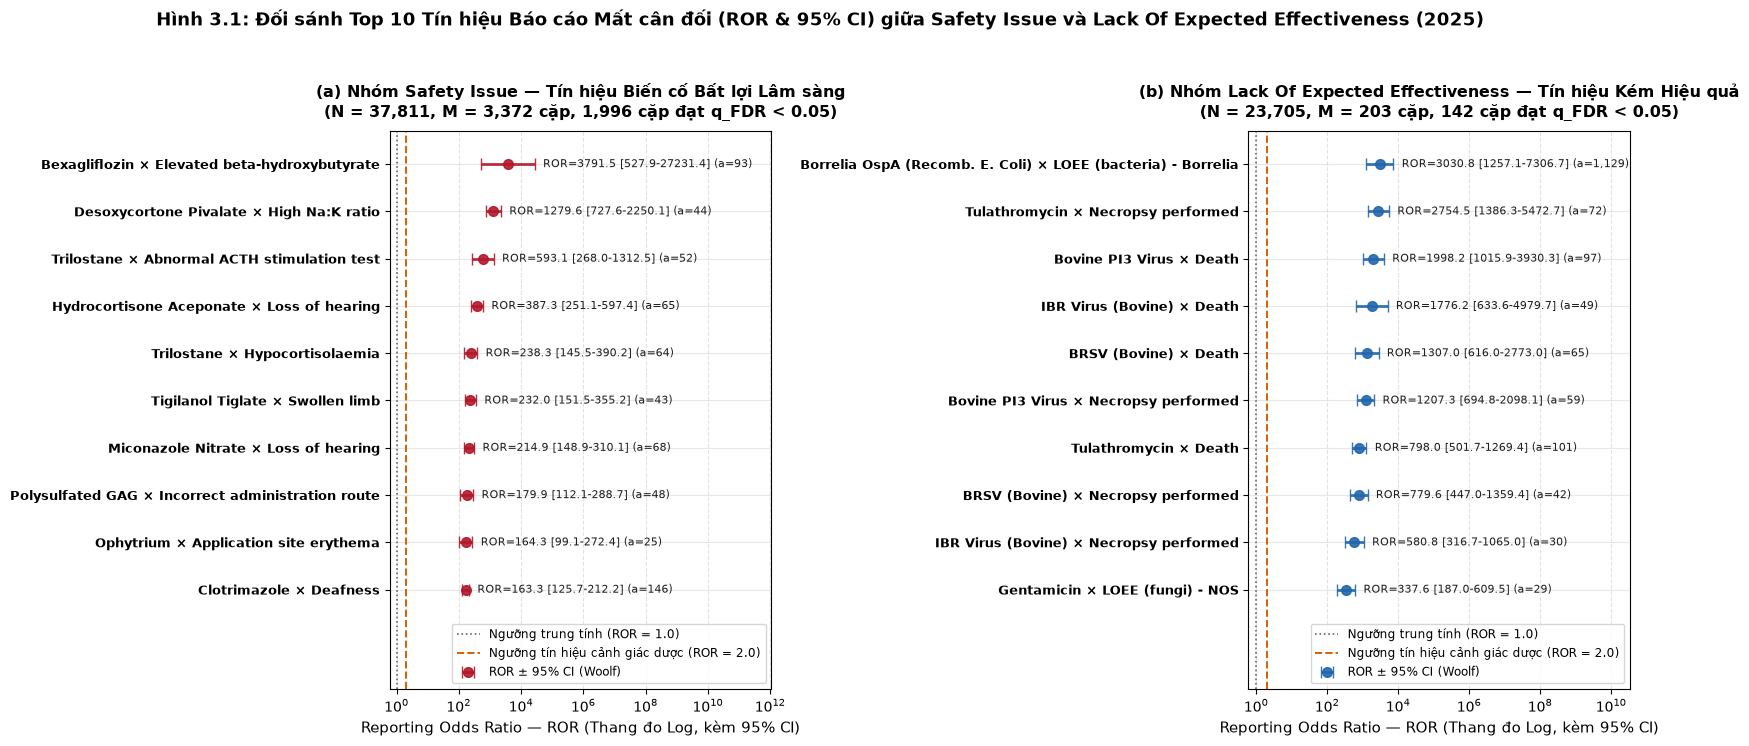

In [6]:
# ===== Hình 3.1: Forest Plot 2 khung đối sánh Top 10 Tín hiệu ROR giữa Safety Issue và Lack Of Expected Effectiveness (D5) =====
fig, axes = plt.subplots(1, 2, figsize=(16.5, 7.2), sharex=False)

def shorten_label_pair(ing_s: pd.Series, rea_s: pd.Series) -> pd.Series:
    ing_clean = (
        ing_s.str.replace("Borrelia Burgdorferi Ospa (Recombinant E. Coli)", "Borrelia OspA (Recomb. E. Coli)", regex=False)
        .str.replace("Polysulfated Glycosaminoglycan", "Polysulfated GAG", regex=False)
        .str.replace("Infectious Bovine Rhinotracheitis Virus", "IBR Virus (Bovine)", regex=False)
        .str.replace("Bovine Respiratory Syncytial Virus", "BRSV (Bovine)", regex=False)
        .str.replace("Bovine Parainfluenza 3 Virus", "Bovine PI3 Virus", regex=False)
    )
    rea_clean = (
        rea_s.str.replace("Lack of efficacy ", "LOEE ", regex=False)
        .str.replace("Abnormal adrenocorticotropic hormone (ACTH) stimulation test", "Abnormal ACTH stimulation test", regex=False)
        .str.replace("High sodium-potassium ratio (Na:K ratio)", "High Na:K ratio", regex=False)
        .str.replace("Elevated betahydroxybutyrate (BHP)", "Elevated beta-hydroxybutyrate", regex=False)
        .str.replace("Incorrect route of drug administration", "Incorrect administration route", regex=False)
    )
    return ing_clean + " × " + rea_clean

def plot_ror_forest_panel(ax, df_sub, title_str, color_hex):
    top10 = df_sub[df_sub["is_signal"]].head(10).iloc[::-1].copy()
    labels = shorten_label_pair(top10["ingredient"], top10["veddra_term_name"])
    y_pos = np.arange(len(top10))

    xerr_low = top10["ROR"] - top10["CI_low"]
    xerr_high = top10["CI_high"] - top10["ROR"]

    ax.errorbar(
        top10["ROR"], y_pos,
        xerr=[xerr_low, xerr_high],
        fmt="o", color=color_hex, ecolor=color_hex,
        elinewidth=2.0, capsize=4, markersize=7, alpha=0.9,
        label="ROR ± 95% CI (Woolf)"
    )
    ax.axvline(1.0, color="#666666", linestyle=":", linewidth=1.2, label="Ngưỡng trung tính (ROR = 1.0)")
    ax.axvline(2.0, color="#d95f02", linestyle="--", linewidth=1.4, label="Ngưỡng tín hiệu cảnh giác dược (ROR = 2.0)")

    ax.set_xscale("log")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=9.0, fontweight="bold")
    ax.set_xlabel("Reporting Odds Ratio — ROR (Thang đo Log, kèm 95% CI)", fontsize=10.5)
    ax.set_title(title_str, fontsize=11.5, fontweight="bold", pad=10)
    ax.grid(True, which="both", axis="x", linestyle="--", alpha=0.35)

    max_ci = float(top10["CI_high"].max())
    x_min = 0.6
    ax.set_xlim(x_min, x_min * ((max_ci / x_min) ** (1.0 / 0.38)))
    ax.set_ylim(-2.1, len(top10) - 0.3)

    for idx, row in enumerate(top10.itertuples()):
        ax.annotate(
            f"ROR={row.ROR:.1f} [{row.CI_low:.1f}-{row.CI_high:.1f}] (a={row.a:,})",
            xy=(row.CI_high, idx),
            xytext=(6, 0),
            textcoords="offset points",
            va="center", ha="left", fontsize=8.2, color="#1f1f1f"
        )
    ax.legend(loc="lower right", fontsize=8.3, frameon=True)

plot_ror_forest_panel(
    axes[0], ror_safety_df,
    f"(a) Nhóm Safety Issue — Tín hiệu Biến cố Bất lợi Lâm sàng\n(N = {ror_safety_df['N_cohort'].iloc[0]:,}, M = {len(ror_safety_df):,} cặp, {ror_safety_df['is_fdr_sig'].sum():,} cặp đạt q_FDR < 0.05)",
    "#b2182b"
)
plot_ror_forest_panel(
    axes[1], ror_loee_df,
    f"(b) Nhóm Lack Of Expected Effectiveness — Tín hiệu Kém Hiệu quả\n(N = {ror_loee_df['N_cohort'].iloc[0]:,}, M = {len(ror_loee_df):,} cặp, {ror_loee_df['is_fdr_sig'].sum():,} cặp đạt q_FDR < 0.05)",
    "#2166ac"
)

plt.suptitle(
    "Hình 3.1: Đối sánh Top 10 Tín hiệu Báo cáo Mất cân đối (ROR & 95% CI) giữa Safety Issue và Lack Of Expected Effectiveness (2025)",
    fontsize=13.2, fontweight="bold", y=1.03
)
plt.tight_layout()
plt.show()


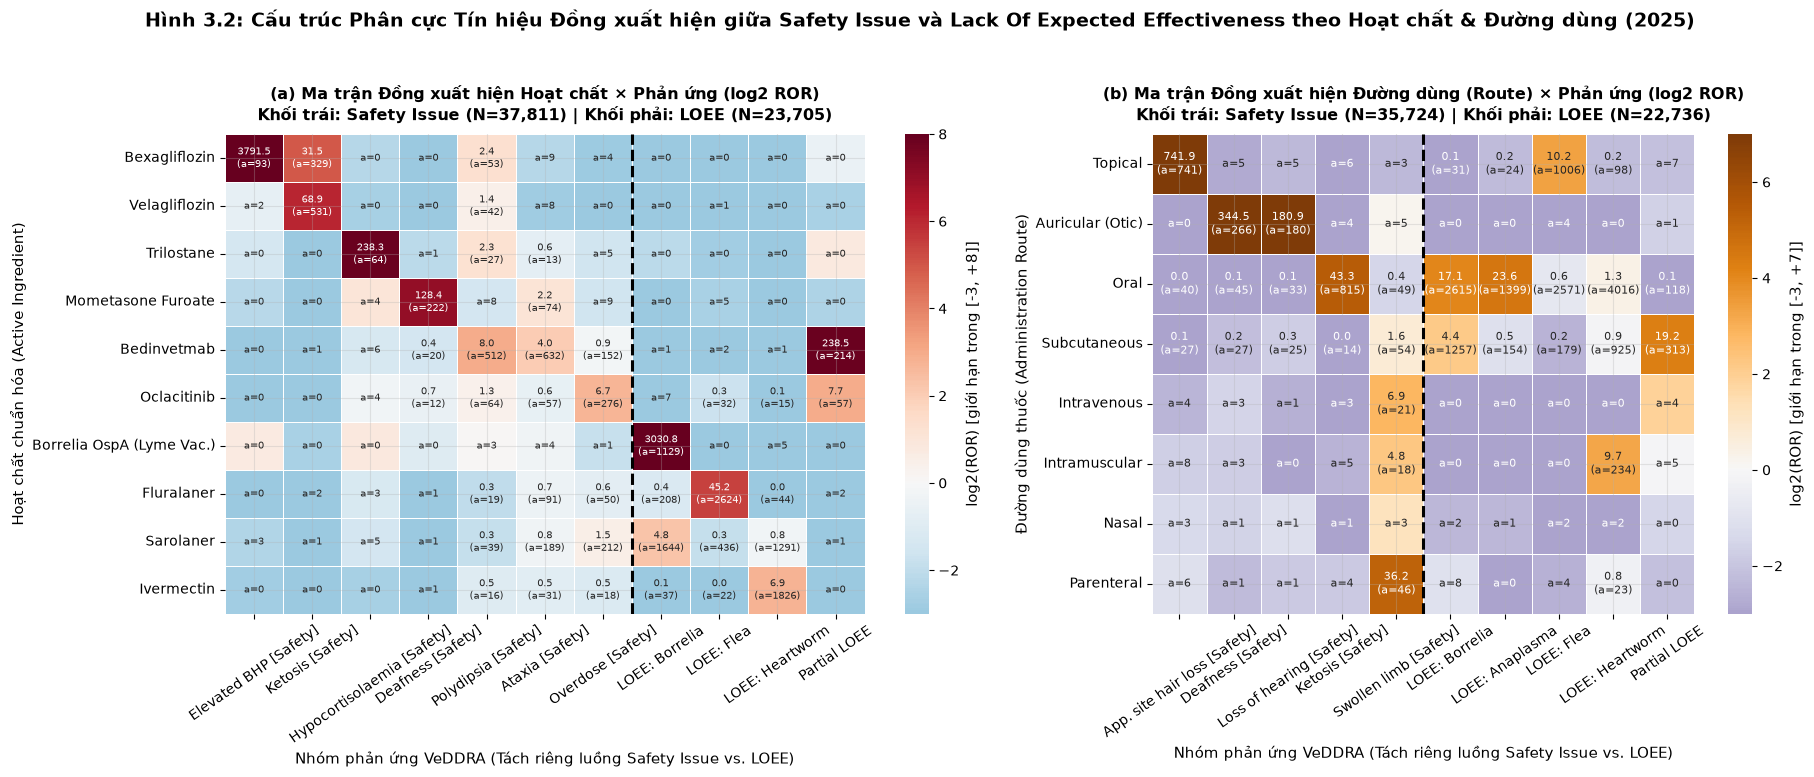

In [7]:
# ===== Hình 3.2: Heatmap xoay trục (Pivot Matrix — D2) cho Hoạt chất x Triệu chứng và Đường dùng x Triệu chứng =====
focus_ingredients = [
    "Bexagliflozin", "Velagliflozin", "Trilostane", "Mometasone Furoate", "Bedinvetmab", "Oclacitinib",
    "Borrelia Burgdorferi Ospa (Recombinant E. Coli)", "Fluralaner", "Sarolaner", "Ivermectin"
]
focus_ing_labels = [
    "Bexagliflozin", "Velagliflozin", "Trilostane", "Mometasone Furoate", "Bedinvetmab", "Oclacitinib",
    "Borrelia OspA (Lyme Vac.)", "Fluralaner", "Sarolaner", "Ivermectin"
]
focus_reactions = [
    "Elevated betahydroxybutyrate (BHP)",
    "Ketosis",
    "Hypocortisolaemia",
    "Deafness",
    "Polydipsia",
    "Ataxia",
    "Overdose",
    "Lack of efficacy (bacteria) - Borrelia",
    "Lack of efficacy (ectoparasite) - flea",
    "Lack of efficacy (endoparasite) - heartworm",
    "Partial lack of efficacy",
]
short_col_labels = [
    "Elevated BHP [Safety]", "Ketosis [Safety]", "Hypocortisolaemia [Safety]", "Deafness [Safety]",
    "Polydipsia [Safety]", "Ataxia [Safety]", "Overdose [Safety]",
    "LOEE: Borrelia", "LOEE: Flea", "LOEE: Heartworm", "Partial LOEE"
]

mat_log2 = np.zeros((len(focus_ingredients), len(focus_reactions)))
mat_annot = np.empty((len(focus_ingredients), len(focus_reactions)), dtype=object)

for i, ing in enumerate(focus_ingredients):
    for j, rea in enumerate(focus_reactions):
        cohort_ids = safety_ids_2025 if j < 7 else loee_ids_2025
        valid_c = set(rep_ing_q3.loc[rep_ing_q3[KEY].isin(cohort_ids), KEY]) & set(rep_rea_q3.loc[rep_rea_q3[KEY].isin(cohort_ids), KEY])
        N_c = len(valid_c)
        e_s = set(rep_ing_q3.loc[rep_ing_q3[KEY].isin(valid_c) & (rep_ing_q3["ingredient"] == ing), KEY])
        r_s = set(rep_rea_q3.loc[rep_rea_q3[KEY].isin(valid_c) & (rep_rea_q3["veddra_term_name"] == rea), KEY])
        a = len(e_s & r_s)
        b = len(e_s - r_s)
        c = len(r_s - e_s)
        d = N_c - a - b - c
        ac, bc, cc, dc = (a + 0.5, b + 0.5, c + 0.5, d + 0.5) if min(a, b, c, d) == 0 else (float(a), float(b), float(c), float(d))
        ror_val = (ac * dc) / (bc * cc)
        mat_log2[i, j] = np.clip(np.log2(ror_val), -3.0, 8.0)
        mat_annot[i, j] = f"{ror_val:.1f}\n(a={a})" if a >= 10 else f"a={a}"

heatmap_ing_df = pd.DataFrame(mat_log2, index=focus_ing_labels, columns=short_col_labels)

focus_routes = ["Topical", "Auricular (Otic)", "Oral", "Subcutaneous", "Intravenous", "Intramuscular", "Nasal", "Parenteral"]
route_reactions = [
    ("Safety", "Application site hair loss", "App. site hair loss [Safety]"),
    ("Safety", "Deafness", "Deafness [Safety]"),
    ("Safety", "Loss of hearing", "Loss of hearing [Safety]"),
    ("Safety", "Ketosis", "Ketosis [Safety]"),
    ("Safety", "Swollen limb", "Swollen limb [Safety]"),
    ("LOEE", "Lack of efficacy (bacteria) - Borrelia", "LOEE: Borrelia"),
    ("LOEE", "Lack of efficacy (bacteria) - Anaplasma", "LOEE: Anaplasma"),
    ("LOEE", "Lack of efficacy (ectoparasite) - flea", "LOEE: Flea"),
    ("LOEE", "Lack of efficacy (endoparasite) - heartworm", "LOEE: Heartworm"),
    ("LOEE", "Partial lack of efficacy", "Partial LOEE"),
]

mat_rt_log2 = np.zeros((len(focus_routes), len(route_reactions)))
mat_rt_annot = np.empty((len(focus_routes), len(route_reactions)), dtype=object)

for i, rt in enumerate(focus_routes):
    for j, (stream, rea, _) in enumerate(route_reactions):
        cohort_ids = safety_ids_2025 if stream == "Safety" else loee_ids_2025
        valid_rt = set(rep_route_q3.loc[rep_route_q3[KEY].isin(cohort_ids), KEY]) & set(rep_rea_q3.loc[rep_rea_q3[KEY].isin(cohort_ids), KEY])
        N_rt_c = len(valid_rt)
        e_s = set(rep_route_q3.loc[rep_route_q3[KEY].isin(valid_rt) & (rep_route_q3["route"] == rt), KEY])
        r_s = set(rep_rea_q3.loc[rep_rea_q3[KEY].isin(valid_rt) & (rep_rea_q3["veddra_term_name"] == rea), KEY])
        a = len(e_s & r_s)
        b = len(e_s - r_s)
        c = len(r_s - e_s)
        d = N_rt_c - a - b - c
        ac, bc, cc, dc = (a + 0.5, b + 0.5, c + 0.5, d + 0.5) if min(a, b, c, d) == 0 else (float(a), float(b), float(c), float(d))
        ror_val = (ac * dc) / (bc * cc)
        mat_rt_log2[i, j] = np.clip(np.log2(ror_val), -3.0, 7.0)
        mat_rt_annot[i, j] = f"{ror_val:.1f}\n(a={a})" if a >= 10 else f"a={a}"

heatmap_rt_df = pd.DataFrame(mat_rt_log2, index=focus_routes, columns=[c[2] for c in route_reactions])

fig, axes = plt.subplots(1, 2, figsize=(18.5, 7.5), gridspec_kw={"width_ratios": [1.18, 1.0]})

sns.heatmap(
    heatmap_ing_df, ax=axes[0], cmap="RdBu_r", center=0.0, vmin=-3.0, vmax=8.0,
    annot=mat_annot, fmt="", annot_kws={"size": 7.5}, linewidths=0.5,
    cbar_kws={"label": "log2(ROR) [giới hạn trong [-3, +8]]"}
)
axes[0].axvline(7, color="black", linewidth=2.2, linestyle="--")
axes[0].set_title(
    "(a) Ma trận Đồng xuất hiện Hoạt chất × Phản ứng (log2 ROR)\nKhối trái: Safety Issue (N=37,811) | Khối phải: LOEE (N=23,705)",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[0].set_xlabel("Nhóm phản ứng VeDDRA (Tách riêng luồng Safety Issue vs. LOEE)", fontsize=10.5)
axes[0].set_ylabel("Hoạt chất chuẩn hóa (Active Ingredient)", fontsize=10.5)
axes[0].tick_params(axis="x", rotation=35)

sns.heatmap(
    heatmap_rt_df, ax=axes[1], cmap="PuOr_r", center=0.0, vmin=-3.0, vmax=7.0,
    annot=mat_rt_annot, fmt="", annot_kws={"size": 7.8}, linewidths=0.5,
    cbar_kws={"label": "log2(ROR) [giới hạn trong [-3, +7]]"}
)
axes[1].axvline(5, color="black", linewidth=2.2, linestyle="--")
axes[1].set_title(
    "(b) Ma trận Đồng xuất hiện Đường dùng (Route) × Phản ứng (log2 ROR)\nKhối trái: Safety Issue (N=35,724) | Khối phải: LOEE (N=22,736)",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[1].set_xlabel("Nhóm phản ứng VeDDRA (Tách riêng luồng Safety Issue vs. LOEE)", fontsize=10.5)
axes[1].set_ylabel("Đường dùng thuốc (Administration Route)", fontsize=10.5)
axes[1].tick_params(axis="x", rotation=35)

plt.suptitle(
    "Hình 3.2: Cấu trúc Phân cực Tín hiệu Đồng xuất hiện giữa Safety Issue và Lack Of Expected Effectiveness theo Hoạt chất & Đường dùng (2025)",
    fontsize=13.5, fontweight="bold", y=1.03
)
plt.tight_layout()
plt.show()


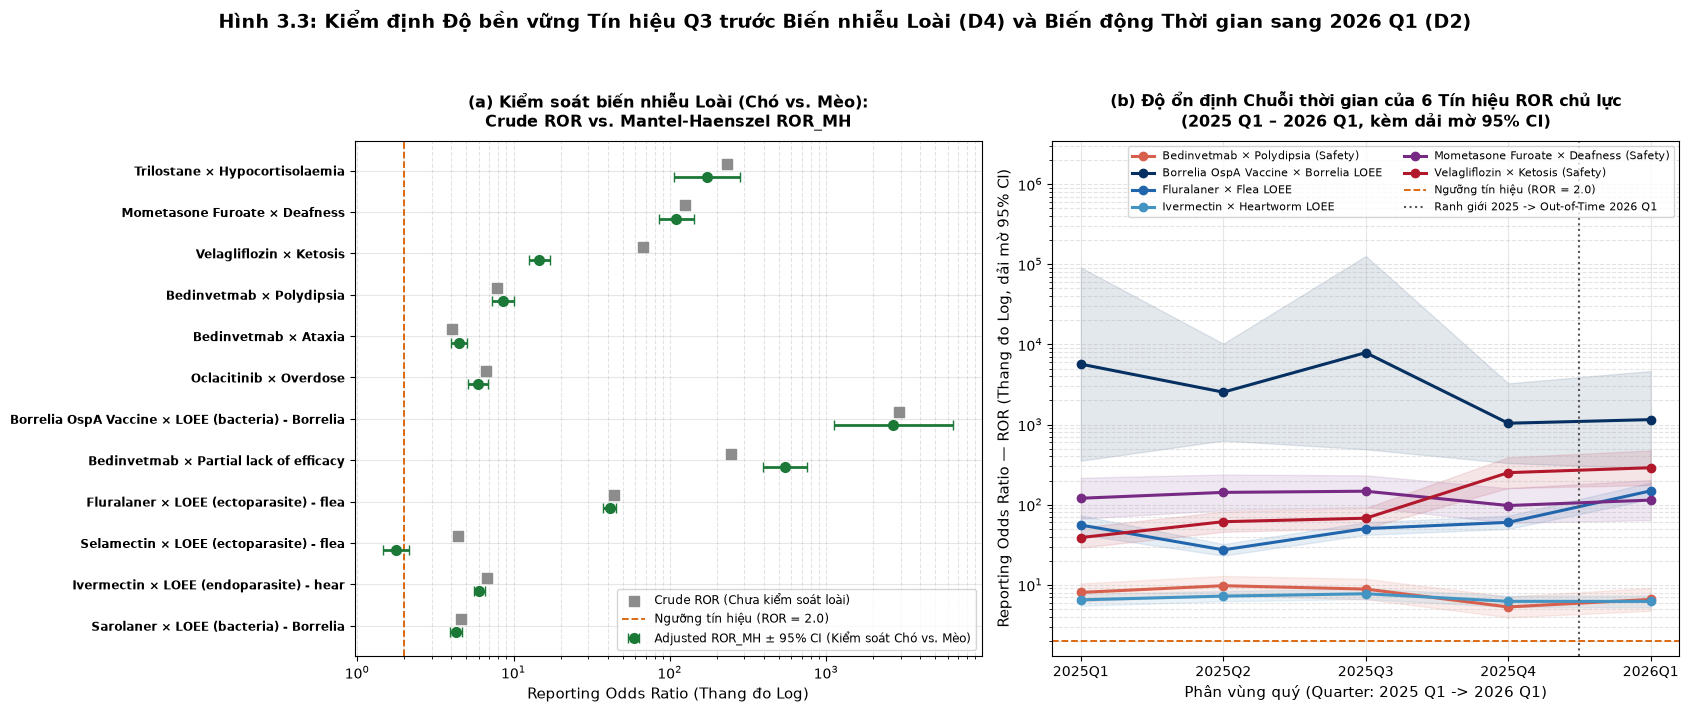

In [8]:
# ===== Hình 3.3: Kiểm soát nhiễu Loài (Dog vs Cat vs Mantel-Haenszel ROR_MH — D4) & Chuỗi thời gian 5 quý (2025Q1-2026Q1 — D2) =====
fig, axes = plt.subplots(1, 2, figsize=(17.0, 6.8))

mh_plot = mh_species_df.iloc[::-1].copy()
mh_ing_short = mh_plot["Hoạt chất"].str.replace("Borrelia Burgdorferi Ospa (Recombinant E. Coli)", "Borrelia OspA Vaccine", regex=False)
mh_rea_short = mh_plot["Phản ứng VeDDRA"].str.replace("Lack of efficacy ", "LOEE ", regex=False).str.slice(0, 26)
mh_labels = mh_ing_short + " × " + mh_rea_short
y_idx = np.arange(len(mh_plot))

axes[0].scatter(mh_plot["Crude ROR"], y_idx + 0.16, color="#8c8c8c", s=55, marker="s", label="Crude ROR (Chưa kiểm soát loài)", zorder=3)
axes[0].errorbar(
    mh_plot["Adjusted ROR_MH"], y_idx - 0.16,
    xerr=[mh_plot["Adjusted ROR_MH"] - mh_plot["95% CI_MH Low"], mh_plot["95% CI_MH High"] - mh_plot["Adjusted ROR_MH"]],
    fmt="o", color="#1b7837", ecolor="#1b7837", elinewidth=2.0, capsize=3.5, markersize=7,
    label="Adjusted ROR_MH ± 95% CI (Kiểm soát Chó vs. Mèo)", zorder=4
)
axes[0].axvline(2.0, color="#d95f02", linestyle="--", linewidth=1.3, label="Ngưỡng tín hiệu (ROR = 2.0)")
axes[0].set_xscale("log")
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(mh_labels, fontsize=8.8, fontweight="bold")
axes[0].set_xlabel("Reporting Odds Ratio (Thang đo Log)", fontsize=10.5)
axes[0].set_title("(a) Kiểm soát biến nhiễu Loài (Chó vs. Mèo):\nCrude ROR vs. Mantel-Haenszel ROR_MH", fontsize=11.5, fontweight="bold", pad=10)
axes[0].grid(True, which="both", axis="x", linestyle="--", alpha=0.35)
axes[0].legend(loc="lower right", fontsize=8.3, frameon=True)

palette_time = {
    "Mometasone Furoate × Deafness (Safety)": "#762a83",
    "Velagliflozin × Ketosis (Safety)": "#b2182b",
    "Bedinvetmab × Polydipsia (Safety)": "#d6604d",
    "Borrelia OspA Vaccine × Borrelia LOEE": "#053061",
    "Fluralaner × Flea LOEE": "#2166ac",
    "Ivermectin × Heartworm LOEE": "#4393c3",
}
q_order = ["2025Q1", "2025Q2", "2025Q3", "2025Q4", "2026Q1"]
for sig_lbl, grp in q3_temporal_df.groupby("signal_label"):
    grp_s = grp.set_index("quarter").loc[q_order].reset_index()
    c_hex = palette_time.get(sig_lbl, "#333333")
    axes[1].plot(grp_s["quarter"], grp_s["ROR"], marker="o", linewidth=2.2, color=c_hex, label=sig_lbl)
    axes[1].fill_between(grp_s["quarter"], grp_s["CI_low"], grp_s["CI_high"], color=c_hex, alpha=0.11)

axes[1].axhline(2.0, color="#d95f02", linestyle="--", linewidth=1.3, label="Ngưỡng tín hiệu (ROR = 2.0)")
axes[1].axvline(3.5, color="#555555", linestyle=":", linewidth=1.5, label="Ranh giới 2025 -> Out-of-Time 2026 Q1")
axes[1].set_yscale("log")
axes[1].set_xlabel("Phân vùng quý (Quarter: 2025 Q1 -> 2026 Q1)", fontsize=10.5)
axes[1].set_ylabel("Reporting Odds Ratio — ROR (Thang đo Log, dải mờ 95% CI)", fontsize=10.5)
axes[1].set_title("(b) Độ ổn định Chuỗi thời gian của 6 Tín hiệu ROR chủ lực\n(2025 Q1 – 2026 Q1, kèm dải mờ 95% CI)", fontsize=11.5, fontweight="bold", pad=10)
axes[1].grid(True, which="both", axis="y", linestyle="--", alpha=0.35)
axes[1].set_ylim(1.3, 3.5e6)
axes[1].legend(loc="upper right", fontsize=7.8, frameon=True, ncol=2)

plt.suptitle(
    "Hình 3.3: Kiểm định Độ bền vững Tín hiệu Q3 trước Biến nhiễu Loài (D4) và Biến động Thời gian sang 2026 Q1 (D2)",
    fontsize=13.5, fontweight="bold", y=1.04
)
plt.tight_layout()
plt.show()


### 4. Trả lời câu hỏi và Thảo Luận

#### 1. Câu trả lời định lượng tường minh (Explicit Answer with Specific Numbers)
Phân tích trên **67,831 báo cáo lâm sàng năm 2025** (trong đó nhóm biến cố bất lợi lâm sàng **`Safety Issue`** chiếm **38,127** ca và nhóm kém/giảm hiệu quả thuốc mong đợi **`Lack Of Expected Effectiveness — LOEE`** chiếm **23,811** ca; sau khi nối có kiểm soát với bảng hoạt chất chuẩn hóa và bảng triệu chứng VeDDRA đạt **67,365** báo cáo khớp hoàn toàn — **99.31%**, và **64,095** báo cáo có đường dùng thuốc xác định từ `drg_q3_valid` — **94.49%**) cho thấy cấu trúc **tín hiệu báo cáo mất cân đối (*disproportionality reporting signals*)** giữa hai luồng **phân cực thành hai mô hình dược lý – lâm sàng hoàn toàn khác biệt**:

- **Ở nhóm `Safety Issue` ($N = 37,811$ báo cáo khớp — không gian kiểm định $M = 3,372$ cặp đạt $n_{\text{exp}} \ge 50, n_{\text{rea}} \ge 50, a \ge 20$; có $1,996$ cặp đạt $q_{\text{FDR}} < 0.05$ & $\text{CI}_{95\%,\text{low}} > 1.0$, trong đó $1,566$ cặp đạt tín hiệu mất cân đối mạnh $\text{ROR} \ge 2.0$):**
  Việc mở rộng không gian kiểm định trên toàn bộ hoạt chất và phản ứng đủ cỡ mẫu (thay vì cắt cứng theo tần suất thô) đã làm lộ diện rõ các **tín hiệu biến cố bất lợi đặc hiệu cơ quan** ở nhóm thuốc chuyên khoa có cỡ mẫu trung bình bên cạnh các thuốc phổ biến:
  1. **Nhóm thuốc nội tiết – chuyển hóa chuyên biệt (`Bexagliflozin`, `Velagliflozin`, `Desoxycortone Pivalate`, `Trilostane`):**
     - Hai thuốc ức chế SGLT2 điều trị đái tháo đường ở mèo ghi nhận tín hiệu mất cân đối chuyển hóa mạnh nhất: **`Bexagliflozin × Elevated betahydroxybutyrate (BHP)`** đứng đầu toàn bảng với $a = 93 / 996$ ca (**9.34%**, $\text{ROR} = 3791.48$, 95% CI: $[527.89, 27231.39]$, $\text{PRR} = 3437.55$, $q_{\text{FDR}} < 10^{-300}$), trong khi **`Velagliflozin`** đồng xuất hiện mạnh với **`Ketosis`** ($a = 531 / 1,294$, **41.04%**, $\text{ROR} = 68.93$, 95% CI: $[59.25, 80.19]$).
     - Thuốc mineralocorticoid điều trị suy vỏ thượng thận (Addison) ở chó **`Desoxycortone Pivalate`** có tín hiệu đồng xuất hiện đặc hiệu với **`High sodium-potassium ratio (Na:K ratio)`** ($a = 44 / 98$, **44.90%**, $\text{ROR} = 1279.56$, 95% CI: $[727.64, 2250.12]$, $\text{PRR} = 705.52$).
     - Ngược lại, thuốc ức chế tổng hợp steroid điều trị hội chứng Cushing ở chó **`Trilostane`** ($n = 519$) ghi nhận cụm tín hiệu suy vỏ thượng thận: **`Abnormal ACTH stimulation test`** ($a = 52$, **10.02%**, $\text{ROR} = 593.09$, 95% CI: $[268.00, 1312.53]$) và **`Hypocortisolaemia`** ($a = 64$, **12.33%**, $\text{ROR} = 238.29$, 95% CI: $[145.52, 390.19]$).
  2. **Cụm hoạt chất trong chế phẩm nhỏ tai trị viêm tai ngoài (`Hydrocortisone Aceponate`, `Miconazole Nitrate`, `Clotrimazole`, `Mometasone Furoate`, `Terbinafine`, `Florfenicol`, `Gentamicin`):**
     - Chiếm 6 vị trí trong Top 15 với cụm tín hiệu mất cân đối đặc hiệu ở cơ quan thính giác – tiền đình: **`Hydrocortisone Aceponate × Loss of hearing`** ($a = 65 / 101$, **64.36%**, $\text{ROR} = 387.27$, 95% CI: $[251.06, 597.38]$), **`Miconazole Nitrate × Loss of hearing`** ($a = 68 / 137$, **49.64%**, $\text{ROR} = 214.87$), **`Clotrimazole × Deafness`** ($a = 146 / 341$, **42.82%**, $\text{ROR} = 163.31$, 95% CI: $[125.69, 212.20]$), **`Mometasone Furoate × Deafness`** ($a = 222 / 892$, **24.89%**, $\text{ROR} = 128.44$, 95% CI: $[99.81, 165.27]$), **`Terbinafine × Head tilt - ear disorder`** ($a = 57 / 436$, $\text{ROR} = 116.95$) và **`Florfenicol × Head tilt - ear disorder`** ($a = 56 / 426$, $\text{ROR} = 115.32$).
  3. **Tín hiệu phản ứng mô tại chỗ, sai sót đường dùng và các thuốc toàn thân quy mô lớn (`Tigilanol Tiglate`, `Polysulfated Glycosaminoglycan`, `Ophytrium`, `Fluralaner`, `Bedinvetmab`, `Oclacitinib`):**
     - Thuốc tiêm nội u điều trị u dưỡng bào ở chó **`Tigilanol Tiglate`** ($n = 125$) có tín hiệu đồng xuất hiện rất cao với phản ứng tại vùng tiêm: **`Swollen limb`** ($a = 43$, **34.40%**, $\text{ROR} = 231.97$, 95% CI: $[151.50, 355.18]$) và **`Wound`** ($a = 39$, **31.20%**, $\text{ROR} = 141.96$, 95% CI: $[93.40, 215.78]$).
     - **`Polysulfated Glycosaminoglycan × Incorrect route of drug administration`** ($a = 48 / 392$, $\text{ROR} = 179.90$), **`Ophytrium × Application site erythema`** ($a = 25 / 94$, $\text{ROR} = 164.28$), và **`Fluralaner × Drug administered at inappropriate site`** ($a = 57 / 2,977$, $\text{ROR} = 113.31$).
     - Ở nhóm thuốc kháng thể đơn dòng và điều hòa miễn dịch có tần suất báo cáo cao, **`Bedinvetmab`** vẫn ghi nhận tín hiệu mất cân đối rõ với **`Polydipsia`** ($a = 512 / 5,898$, $\text{ROR} = 7.95$, 95% CI: $[6.94, 9.11]$) và **`Ataxia`** ($a = 632 / 5,898$, $\text{ROR} = 4.00$), còn **`Oclacitinib`** gắn với **`Overdose`** ($a = 276 / 2,079$, $\text{ROR} = 6.67$).

- **Ở nhóm `Lack Of Expected Effectiveness — LOEE` ($N = 23,705$ báo cáo khớp — không gian kiểm định $M = 203$ cặp; có $142$ cặp đạt $q_{\text{FDR}} < 0.05$ & $\text{CI}_{95\%,\text{low}} > 1.0$, trong đó $107$ cặp đạt $\text{ROR} \ge 2.0$):**
  1. **Hợp nhất kháng nguyên vắc-xin phòng bệnh Lyme (`Borrelia Burgdorferi Ospa (Recombinant E. Coli)`):** Sau khi hợp nhất tên thương mại `Recombitek Lyme - 2126.R0` ($a = 270$) với hệ chủng biểu hiện `Recombinant E. Coli (Bl21/Ecl19)` ($a = 859$) về cùng thực thể kháng nguyên OspA tái tổ hợp, cặp **`Borrelia Burgdorferi Ospa (Recombinant E. Coli) × Lack of efficacy (bacteria) - Borrelia`** dẫn đầu bảng LOEE với $a = 1,129 / 1,134$ báo cáo (**99.56%**, $\text{ROR} = 3030.77$, 95% CI: $[1257.14, 7306.72]$, $\text{PRR} = 14.36$, $q_{\text{FDR}} < 10^{-300}$), loại bỏ hoàn toàn hiện tượng suy biến $b = 0$ do tách đôi tên thuốc.
  2. **Tín hiệu thất bại bảo vệ/điều trị bệnh hô hấp phức hợp ở đàn bò (`Tulathromycin`, `Bovine Parainfluenza 3 Virus`, `Infectious Bovine Rhinotracheitis Virus`, `Bovine Respiratory Syncytial Virus`):** Trong luồng báo cáo `LOEE` ở gia súc, kháng sinh **`Tulathromycin`** ($n = 128$) và các kháng nguyên vắc-xin virus hô hấp bò đồng xuất hiện mạnh với **`Necropsy performed`** và **`Death`** (`Tulathromycin × Necropsy performed`: $a = 72$, **56.25%**, $\text{ROR} = 2754.47$, 95% CI: $[1386.35, 5472.73]$; `Tulathromycin × Death`: $a = 101$, **78.91%**, $\text{ROR} = 798.04$; `Bovine Parainfluenza 3 Virus × Death`: $a = 97 / 107$, **90.65%**, $\text{ROR} = 1998.20$; `Infectious Bovine Rhinotracheitis Virus × Death`: $a = 49 / 53$, $\text{ROR} = 1776.25$; `Bovine Respiratory Syncytial Virus × Death`: $a = 65 / 73$, $\text{ROR} = 1307.01$). Cần phân biệt rõ về mặt lâm sàng: đây là các báo cáo được nộp dưới phân loại **kém hiệu quả thuốc (`LOEE`)** khi phác đồ kháng sinh hoặc tiêm phòng vắc-xin không ngăn chặn được đợt bùng phát bệnh hô hấp ở đàn bò dẫn đến tử vong và mổ khám bệnh tích, chứ không phải độc tính cấp tính của thuốc.
  3. **Tín hiệu kém hiệu quả ở thuốc nhỏ tai kháng nấm, thuốc nội khoa mạn tính và thuốc phòng trị ký sinh trùng (`Gentamicin`, `Posaconazole`, `Mometasone Furoate`, `Velagliflozin`, `Ilunocitinib`, `Bedinvetmab`, `Fluralaner`, `Ivermectin`, `Sarolaner`):**
     - Các thành phần thuốc nhỏ tai phối hợp ghi nhận tín hiệu mất cân đối với **`Lack of efficacy (fungi) - NOS`**: `Gentamicin` ($a = 29 / 121$, $\text{ROR} = 337.60$), `Posaconazole` ($a = 26 / 102$, $\text{ROR} = 322.65$) và `Mometasone Furoate` ($a = 32 / 157$, $\text{ROR} = 317.02$).
     - Các thuốc điều trị bệnh lý mạn tính ghi nhận tín hiệu đồng xuất hiện cao với **`Lack of efficacy - NOS`** hoặc **`Partial lack of efficacy`**: `Velagliflozin × LOEE - NOS` ($a = 166 / 172$, **96.51%**, $\text{ROR} = 317.55$, 95% CI: $[140.44, 718.02]$), `Ilunocitinib × LOEE - NOS` ($a = 127 / 132$, **96.21%**, $\text{ROR} = 285.64$), và `Bedinvetmab × Partial lack of efficacy` ($a = 214 / 329$, **65.05%**, $\text{ROR} = 238.47$, 95% CI: $[182.09, 312.30]$).
     - Ở nhóm thuốc ký sinh trùng có số lượng báo cáo lớn nhất: **`Fluralaner × LOEE (ectoparasite) - flea`** ($a = 2,624 / 3,546$, **74.00%**, $\text{ROR} = 45.24$, 95% CI: $[41.14, 49.76]$), **`Ivermectin × LOEE (endoparasite) - heartworm`** ($a = 1,826$, $\text{ROR} = 6.72$), và **`Sarolaner × LOEE (bacteria) - Borrelia`** ($a = 1,644$, $\text{ROR} = 4.77$).

- **Sự phân cực theo Đường dùng thuốc (`route`) khi tách riêng hai luồng `Safety Issue` và `LOEE` (Bảng 3A & 3B, Hình 3.2b):**
  - **Trong luồng `Safety Issue` ($N = 35,724$, $M = 1,291$ cặp kiểm định; $592$ cặp đạt $q_{\text{FDR}} < 0.05$ & $\text{CI}_{95\%,\text{low}} > 1.0$; $427$ cặp đạt $\text{ROR} \ge 2.0$):** Các tín hiệu báo cáo mất cân đối phản ánh đặc trưng vị trí giải phẫu tiếp xúc với thuốc:
    - Đường bôi ngoài da (**`Topical`**, $n = 3,917$) gắn chặt với biến cố tổn thương da tại chỗ bôi và hành vi liếm thuốc: `Application site hair loss` ($a = 741$, **18.92%**, $\text{ROR} = 741.86$, 95% CI: $[397.07, 1386.04]$), `Licking at application site` ($a = 65$, $\text{ROR} = 268.34$), `Drug administered at inappropriate site` ($a = 61$, $\text{ROR} = 251.57$), `Application site alopecia` ($a = 223$, $\text{ROR} = 239.96$), `Application site burn` ($a = 79$, $\text{ROR} = 163.66$), `Application site lesion` ($a = 80$, $\text{ROR} = 132.61$) và `Application site scab` ($a = 197$, $\text{ROR} = 93.52$).
    - Đường nhỏ tai (**`Auricular (Otic)`**, $n = 1,251$) gắn đặc hiệu với biến cố thính giác – tiền đình: `Deafness` ($a = 266$, **21.26%**, $\text{ROR} = 344.52$, 95% CI: $[230.73, 514.44]$), `Loss of hearing` ($a = 180$, **14.39%**, $\text{ROR} = 180.89$), `Head tilt - ear disorder` ($a = 85$, $\text{ROR} = 125.58$) và `Head shake - ear disorder` ($a = 74$, $\text{ROR} = 52.80$).
    - Đường uống (**`Oral`**, $n = 22,849$) trong nhóm Safety nổi bật với tín hiệu rối loạn chuyển hóa toàn thân: `Elevated betahydroxybutyrate (BHP)` ($a = 90$, $\text{ROR} = 102.40$) và `Ketosis` ($a = 815$, $\text{ROR} = 43.26$).
  - **Trong luồng `Lack Of Expected Effectiveness` ($N = 22,736$, $M = 64$ cặp kiểm định; $31$ cặp đạt $q_{\text{FDR}} < 0.05$ & $\text{CI}_{95\%,\text{low}} > 1.0$; $24$ cặp đạt $\text{ROR} \ge 2.0$):**
    - Đường nhỏ mũi (**`Nasal`**, $n = 82$, chủ yếu là vắc-xin hô hấp bò nhỏ mũi) và tiêm dưới da (**`Subcutaneous`**, $n = 4,628$) đồng xuất hiện mạnh với hậu quả thất bại bảo vệ đàn gia súc (`Nasal × Death`: $a = 57$, **69.51%**, $\text{ROR} = 424.59$; `Subcutaneous × Necropsy performed`: $a = 81$, $\text{ROR} = 322.56$; `Nasal × Necropsy performed`: $a = 33$, $\text{ROR} = 310.69$; `Nasal × LOEE - NOS`: $a = 60$, $\text{ROR} = 32.90$) và giảm đáp ứng một phần ở thuốc tiêm dưới da (`Subcutaneous × Partial lack of efficacy`: $a = 313$, $\text{ROR} = 19.24$).
    - Đường nhỏ tai (**`Auricular (Otic)`**, $n = 182$) gắn với thất bại điều trị nhiễm khuẩn tại chỗ: `LOEE (bacteria) - NOS` ($a = 43$, $\text{ROR} = 154.74$) và `LOEE - NOS` ($a = 120$, $\text{ROR} = 24.14$).
    - Đường uống (**`Oral`**, $n = 17,962$) gắn với báo cáo thất bại dự phòng tác nhân truyền qua ve/bọ chét: `LOEE (bacteria) - Ehrlichia` ($a = 665$, $\text{ROR} = 61.14$), `LOEE (bacteria) - Anaplasma` ($a = 1,399$, $\text{ROR} = 23.64$) và `LOEE (bacteria) - Borrelia` ($a = 2,615$, **14.56%**, $\text{ROR} = 17.14$); trong khi đường bôi (**`Topical`**, $n = 1,697$) gắn với `LOEE (ectoparasite) - flea` ($a = 1,006$, **59.28%**, $\text{ROR} = 10.15$) và đường tiêm bắp (**`Intramuscular`**, $n = 326$) gắn với `LOEE (endoparasite) - heartworm` ($a = 234$, **71.78%**, $\text{ROR} = 9.69$).

- **Kết quả kiểm soát biến nhiễu Loài (D4) & Độ ổn định sang 2026 Q1 (D2):**
  - Khi phân tầng theo **Chó (`Dog`)** vs. **Mèo (`Cat`)** và tính $\text{ROR}_{\text{MH}}$ trên số đếm nguyên gốc (Bảng 4 & Hình 3.3a):
    1. `Velagliflozin × Ketosis` (thuốc chỉ định chuyên biệt cho Mèo: $a_{\text{Cat}} = 530, a_{\text{Dog}} = 0$) giảm từ Crude $\text{ROR} = 66.98$ xuống $\text{ROR}_{\text{MH}} = 14.64$ (95% CI: $[12.57, 17.06]$, loại bỏ **$-78.1\%$** độ phóng đại giả tạo do gộp mẫu số của Chó). Tương tự, các thuốc chủ yếu dùng trên Chó được hiệu chỉnh về đúng mẫu số loài như `Trilostane × Hypocortisolaemia` (Crude $\text{ROR} = 231.87 \rightarrow \text{ROR}_{\text{MH}} = 172.95$, 95% CI: $[105.62, 283.21]$, $-25.4\%$), `Mometasone Furoate × Deafness` (Crude $\text{ROR} = 125.12 \rightarrow \text{ROR}_{\text{MH}} = 109.84$, 95% CI: $[85.04, 141.89]$, $-12.2\%$), và `Borrelia Burgdorferi Ospa (Recombinant E. Coli) × LOEE - Borrelia` (Crude $\text{ROR} = 2939.73 \rightarrow \text{ROR}_{\text{MH}} = 2689.23$, 95% CI: $[1115.46, 6483.42]$, $-8.5\%$).
    2. Ngược lại, `Bedinvetmab × Partial lack of efficacy` ($a_{\text{Dog}} = 214, a_{\text{Cat}} = 0$) tăng từ Crude $\text{ROR} = 244.78$ lên $\text{ROR}_{\text{MH}} = 545.22$ (95% CI: $[394.20, 754.09]$, **$+122.7\%$**), và `Bedinvetmab × Polydipsia` tăng từ $7.78$ lên $\text{ROR}_{\text{MH}} = 8.58$ ($+10.2\%$) sau khi loại bỏ mẫu số báo cáo của Mèo.
    3. **Nhiễu loài đảo chiều ở `Selamectin × LOEE - flea`:** Dù có Crude $\text{ROR} = 4.44$, khi phân tầng theo loài thì ở Mèo ($a_{\text{Cat}} = 121$ — loài chỉ định chính của *Selamectin*) tỷ số chênh chỉ là $\text{ROR}_{\text{Cat}} = 0.88$, kéo **$\text{ROR}_{\text{MH}}$ giảm $-60.0\%$ xuống còn $1.77$ (95% CI: $[1.46, 2.15]$, dưới ngưỡng tín hiệu $2.0$)**; trong khi **11/12 tín hiệu chủ lực còn lại đều giữ vững $\text{ROR}_{\text{MH}} \ge 4.27$ và cận dưới 95% CI $\ge 3.93$**.
  - Chuỗi thời gian 5 quý (`2025Q1` $\rightarrow$ `2026Q1`, Bảng 5 & Hình 3.3b) xác nhận cả 6 tín hiệu theo dõi đều duy trì ổn định trên ngưỡng $\text{ROR} > 2.0$ khi bước sang quý kiểm thử độc lập `2026Q1` (`Borrelia OspA Vaccine × Borrelia LOEE`: $\text{ROR} = 1151.93$; `Velagliflozin × Ketosis`: $\text{ROR} = 289.20$; `Fluralaner × Flea LOEE`: $\text{ROR} = 148.80$; `Mometasone Furoate × Deafness`: $\text{ROR} = 114.09$; `Bedinvetmab × Polydipsia`: $\text{ROR} = 6.58$; `Ivermectin × Heartworm LOEE`: $\text{ROR} = 6.21$).

#### 2. Ý nghĩa thực tiễn & Phát hiện bất ngờ (Practical Meaning & Surprises)
- **Giá trị của việc mở rộng không gian giả thuyết ($n_{\text{exp}} \ge 50, n_{\text{rea}} \ge 50, a \ge 20$) và tách riêng luồng `Safety Issue` vs. `LOEE`:** Nếu chỉ lọc Top 15 hoạt chất có tổng số báo cáo lớn nhất hoặc gộp chung hai luồng, toàn bộ bảng kết quả sẽ bị chi phối bởi các thuốc diệt ký sinh trùng và bỏ sót các **tín hiệu báo cáo mất cân đối đặc hiệu cơ quan** cực kỳ quan trọng cho lâm sàng thú y như: theo dõi thể ceton máu (`BHP` / `Ketosis`) khi kê đơn thuốc ức chế SGLT2 (`Bexagliflozin`, `Velagliflozin`) cho mèo; kiểm tra điện giải $\text{Na:K}$ và nghiệm pháp kích thích ACTH khi điều trị bệnh nội tiết thượng thận bằng `Desoxycortone Pivalate` hoặc `Trilostane` ở chó; và kiểm tra tính toàn vẹn màng nhĩ / theo dõi thính lực khi sử dụng thuốc nhỏ tai chứa `Mometasone Furoate`, `Clotrimazole`, `Gentamicin`, `Terbinafine`, `Florfenicol`.

#### 3. Giới hạn của phân tích (Limitations)
- **Tín hiệu báo cáo mất cân đối thống kê không đồng nghĩa với quan hệ nhân quả hay tỷ lệ mắc bệnh (*Disproportionality Signal $\neq$ Causality or Incidence*):** Dữ liệu openFDA CVM là hệ thống báo cáo tự nguyện hậu mại (*spontaneous reporting system*), không có mẫu số tổng số cá thể vật nuôi sử dụng thuốc an toàn và chịu ảnh hưởng của thiên lệch báo cáo (*stimulated reporting*, *under-reporting*). Do đó, giá trị $\text{ROR}$ cao chỉ xác lập **tín hiệu báo cáo mất cân đối mạnh về mặt thống kê (*strong statistical disproportionality signal*)** để ưu tiên thẩm định an toàn thuốc, tuyệt đối không dùng để kết luận thuốc trực tiếp "gây ra" phản ứng hay đánh giá nguy cơ tuyệt đối (*absolute risk*).
- **Đồng phơi nhiễm trong chế phẩm phối hợp (*Combination Drug Co-exposure*):** Với các thuốc nhỏ tai phối hợp 3 hoạt chất (như `Gentamicin + Mometasone Furoate + Clotrimazole` hoặc `Florfenicol + Terbinafine + Mometasone Furoate`) hay viên nhai trị ký sinh trùng đa thành phần, việc tách hoạt chất sẽ ghi nhận đồng xuất hiện cho từng thành phần trong chế phẩm, đòi hỏi phải kết hợp dược lý học chuyên sâu khi quy kết vai trò của từng hoạt chất đơn lẻ.


---
## Điều hướng liên kết
- **Trước:** [Câu hỏi Q2](02_q2_analysis.ipynb)
- **Master Hub:** [Notebook 02: Tổng quan & Ma trận D1–D6](02_analysis.ipynb)
- **Tiếp theo:** [Câu hỏi Q4](02_q4_analysis.ipynb)